# Pemodelan 02 — Pemilihan Konfigurasi di Bagian Validasi

Notebook ini memilih konfigurasi CNN-LSTM dan pembandingnya hanya dari bagian
validasi. Tahap A mengunci faktor data satu per satu (panjang jendela, sumber
hujan, transformasi hujan, dan varian pos); tahap B menuning hiperparameter;
ablasi dilaporkan pada konfigurasi terpilih. Bagian uji tidak dibuka di notebook
ini, dan konfigurasi akhirnya ditulis ke `modeling/konfigurasi_final.json`.

Urutan tiap tahap sama dengan notebook 01: baris `Dasar:` yang merujuk ke kunci
di `references/README.md`, tampilkan data atau masalahnya, lalu olah dan
tampilkan hasilnya.

## Informasi umum

| | |
|---|---|
| Data | Tensor hasil preprocessing; pilihan di luar pilihan dasar disusun ulang dengan fungsi `susun` preprocessing tahap 24 |
| Pilihan dasar | V17, jendela 14 hari, hujan Daymet tergeser, log1p |
| Bagian yang dipakai | Latih (kode 0) dan validasi (kode 1) saja |
| Model tahap A | CNN-LSTM pada pengaturan tengah (lr 0,001; 64 unit; 2 lapisan LSTM; dropout 0,25; kernel 2; 1 lapisan konvolusi) |
| Seed | 0, 1, 2 |
| Kriteria | Rata-rata NSE validasi horizon 1–3, dirata-rata atas seed |
| Perangkat | GPU NVIDIA GeForce RTX 4060; run dari perangkat lain tidak dipakai ulang |
| Log | Setiap run dicatat di `modeling/hasil/log_run.csv` |

## Susunan notebook

| Bagian | Tahap | Isi |
|---|---|---|
| I | 1–2 | Tensor untuk pilihan data dan aturan pemilihan |
| II | 3–6 | Tahap A: jendela (A1), sumber hujan (A2), transformasi hujan (A3), varian pos (A4) |
| III | 11–14 | Tahap B: pencarian Latin hypercube, finalis, dan kalibrasi MC Dropout |
| IV | 15–21 | Tahap R: hujan stasiun v2 (R0–R5), R3 per wilayah DAS, model terpilih dengan data R3_titik, ablasi kontribusi data, kontrol atribut acak, perbandingan CNN-LSTM dengan ARIMA, uji suku τ⁻¹ MC Dropout |
| V | — | Ablasi dan `konfigurasi_final.json` (menyusul) |

---
## Persiapan

Dasar: deskriptif, tidak ada keputusan metodologis

Sel pertama berisi import, konstanta, dan fungsi bantu. Sel kedua adalah sel
gaya gambar yang sama dengan notebook preprocessing dan notebook 01.

In [1]:
import json, os, sys, time, warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
MULAI_JALAN = time.time()

# --- lokasi folder: notebook bisa dijalankan dari root repo maupun dari folder modeling/
ROOT = Path.cwd() if (Path.cwd() / "processed").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "modeling"))
import pemodelan as pm
from pemodelan import muat_latih_val, metrik, ke_m3s, jalankan, baca_log

FIGUR, HASIL = pm.FIGUR, pm.HASIL
PERIODE, n_hari = pm.PERIODE, pm.N_HARI
i_latih, i_val = pm.I_LATIH, pm.I_VAL          # batas 70:15:15, lihat tahap 22 preprocessing
TARGET, HORIZON = pm.TARGET, pm.HORIZON
NOTEBOOK = "02_pemilihan"
SEED_SELEKSI = [0, 1, 2]                        # 3 seed untuk seleksi (brief bagian 1)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

def koma(x, _=None, d=2):
    # Angka dengan koma desimal.
    return f"{x:.{d}f}".replace(".", ",")

def ribu(x):
    # Bilangan bulat dengan titik pemisah ribuan.
    return f"{int(round(x)):,}".replace(",", ".")

def sumbu_koma(ax, sumbu="y", d=1):
    f = FuncFormatter(lambda x, _: koma(x, d=d))
    (ax.yaxis if sumbu == "y" else ax.xaxis).set_major_formatter(f)

import keras, tensorflow as tf
tf.get_logger().setLevel("ERROR")
print(f"TensorFlow {tf.__version__}, Keras {keras.__version__}, perangkat: "
      f"{', '.join(d.device_type for d in tf.config.list_physical_devices())}")
print(f"mesin: {pm.mesin()}")
print(f"batas latih/validasi: {PERIODE[i_latih].date()}, validasi/uji: {PERIODE[i_val].date()}")

TensorFlow 2.20.0, Keras 3.15.1, perangkat: CPU, GPU
mesin: x86_64-NVIDIA GeForce RTX 4060
batas latih/validasi: 2017-07-02, validasi/uji: 2021-04-02


### Gaya gambar

Semua gambar di notebook memakai sel ini. Aturannya:

- **Latar dan teks.** Latar putih, teks judul, label, dan angka sumbu abu-abu gelap
  (`#333333`), gridline tipis abu-abu muda. Ukuran huruf dasar 10 pt.
- **Palet kategorikal.** Enam warna Okabe–Ito versi pudar, yang tetap bisa dibedakan
  oleh pembaca buta warna. Satu gambar memakai paling banyak enam warna. Metode
  pengisian yang sama memakai warna yang sama di semua gambar (`WARNA_METODE`):
  regresi dinamis hijau, MOVE.1 oranye, interpolasi linear abu-abu tua, regresi
  log-log biru langit, DAR ungu, dan isian dari sumber lain pada hari yang sama
  (gridMET, tambal nol dari tetangga) merah bata. Dua versi dari metode yang sama
  dibedakan dengan jenis garis dan penanda. Debit terukur biru, hujan biru langit,
  deret donor abu-abu, nilai berkode `A:e` ungu, dan rentang hari kosong diarsir
  oranye redup.
- **Ketersediaan data.** Dua warna: tersedia biru muda (`#9ecae1`), kosong oranye
  redup (`#d9822b`), dan bulan yang sebagian harinya kosong memakai gradasi di
  antara keduanya.
- **Besaran kontinu** (korelasi, jarak, hujan, luas). Colormap sekuensial satu
  hue (`Blues`), dengan rentang yang disesuaikan dengan data supaya perbedaannya
  terlihat. Angka di dalam sel berwarna gelap atau putih menurut terang latarnya.
- **Batas pembagian data.** Batas latih–validasi dan validasi–uji digambar sebagai
  garis abu-abu putus-putus.
- **Penyimpanan.** Setiap gambar disimpan dengan `simpan_gambar()` ke folder
  `figur/` (PNG, 200 dpi, latar putih), lalu ditampilkan.

In [2]:
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb

TEKS = "#333333"        # judul, label, angka sumbu
GRID = "#e3e3e3"        # gridline tipis
BATAS = "#8c8c8c"       # batas latih/validasi/uji

# palet kategorikal: Okabe–Ito versi pudar (6 warna)
PALET = {"biru": "#3d78a8", "oranye": "#d9822b", "hijau": "#3e9c80",
         "merah": "#c4664a", "ungu": "#a87a9f", "langit": "#86b8dc"}
ABU, ABU_TUA, ABU_MUDA = "#9a9a9a", "#5f5f5f", "#cfcfcf"

# peran warna yang dipakai di banyak gambar
WARNA = {
    "utama":  PALET["biru"],     # debit terukur, pos yang dipakai
    "aksen":  PALET["merah"],    # penanda dan garis bantu
    "abu":    ABU,               # pos yang tidak dipakai, deret donor, elemen sekunder
    "hujan":  PALET["langit"],   # hujan
    "risiko": "#f3cfa6",         # isi kotak tahap berisiko kebocoran (oranye pudar)
    "netral": "#e8f0f7",         # isi kotak diagram biasa
    "perkiraan": PALET["ungu"],  # nilai berkode A:e (hasil perkiraan USGS)
    "kosong": "#d9822b",         # hari kosong (sama dengan warna kosong pada peta ketersediaan)
}
# metode pengisian: warna, jenis garis, dan penanda yang sama di semua gambar
WARNA_METODE = {
    "linear": ABU_TUA, "regresi log-log": PALET["langit"], "MOVE.1": PALET["oranye"],
    "DAR φ=0,89": PALET["ungu"], "DAR φ fit": PALET["ungu"],
    "regresi dinamis": PALET["hijau"], "regresi dinamis kausal": PALET["hijau"],
    "sumber lain": PALET["merah"],          # gridMET untuk kabisat Daymet, tambal nol dari tetangga GHCN
}
GARIS_METODE = {"DAR φ fit": "--", "regresi dinamis kausal": "--"}
PENANDA_METODE = {"linear": "o", "regresi log-log": "s", "MOVE.1": "D", "DAR φ=0,89": "v", "DAR φ fit": "^",
                  "regresi dinamis": "P", "regresi dinamis kausal": "X", "sumber lain": "s"}

def potong_cmap(nama, a=0.0, b=1.0):
    """Bagian a..b dari colormap, misalnya supaya garis berwarna terang tetap terlihat di latar putih."""
    return LinearSegmentedColormap.from_list(f"{nama}_{a}_{b}", plt.get_cmap(nama)(np.linspace(a, b, 256)))

CMAP_TERSEDIA = LinearSegmentedColormap.from_list("tersedia", ["#d9822b", "#9ecae1"])   # kosong -> tersedia
CMAP_SEKUENSIAL = plt.get_cmap("Blues")                 # korelasi, hujan, jarak (dibalik)
CMAP_GARIS = potong_cmap("Blues", 0.35, 0.95)           # garis yang diwarnai menurut besaran kontinu

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "text.color": TEKS, "axes.labelcolor": TEKS, "axes.titlecolor": TEKS,
    "xtick.color": TEKS, "ytick.color": TEKS, "axes.edgecolor": "#8c8c8c", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "image.cmap": "Blues",
    "axes.prop_cycle": cycler(color=list(PALET.values())),
})

def simpan_gambar(fig, nama):
    """Simpan gambar ke figur/<nama>.png (200 dpi, latar putih), lalu tampilkan."""
    fig.savefig(FIGUR / f"{nama}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

def warna_teks(latar):
    """Warna angka di atas sel: abu-abu gelap di latar terang, putih di latar gelap."""
    r, g, b = to_rgb(latar)
    return TEKS if 0.299 * r + 0.587 * g + 0.114 * b > 0.55 else "white"

def heatmap(ax, M, cmap, vmin, vmax, fmt=None, ukuran=9, tebal=None, lewati=None, aspect="equal", extent=None):
    """imshow tanpa grid dan bingkai; bila fmt diberikan, nilai ditulis di tiap sel dengan warna otomatis.
    tebal: sel yang angkanya ditebalkan; lewati: sel yang angkanya tidak ditulis (boolean, bentuk sama dengan M)."""
    A = np.asarray(M, float)
    cm_, nrm = plt.get_cmap(cmap), Normalize(vmin, vmax)
    im = ax.imshow(A, cmap=cm_, norm=nrm, aspect=aspect, interpolation="nearest", extent=extent)
    ax.grid(False)
    for s_ in ax.spines.values():
        s_.set_visible(False)
    if fmt is not None:
        for i in range(A.shape[0]):
            for j in range(A.shape[1]):
                if np.isfinite(A[i, j]) and not (lewati is not None and lewati[i, j]):
                    ax.text(j, i, fmt(A[i, j]), ha="center", va="center", fontsize=ukuran,
                            color=warna_teks(cm_(nrm(A[i, j]))),
                            fontweight="bold" if tebal is not None and tebal[i, j] else "normal")
    return im

def batas_bagian(ax, ke_x=lambda t: t, label=True, y_label=1.01):
    """Garis putus-putus abu-abu di batas latih-validasi dan validasi-uji; label bagian di atas sumbu."""
    x_l, x_v = ke_x(PERIODE[i_latih]), ke_x(PERIODE[i_val])
    for x_ in (x_l, x_v):
        ax.axvline(x_, color=BATAS, lw=1.0, ls="--", zorder=1)
    if label:
        tr = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
        for t_, teks in [(PERIODE[i_latih // 2], "latih"), (PERIODE[(i_latih + i_val) // 2], "validasi"),
                         (PERIODE[(i_val + n_hari) // 2], "uji")]:
            ax.text(ke_x(t_), y_label, teks, transform=tr, ha="center", va="bottom", fontsize=9, color=ABU_TUA)

def bagian_dari(t):
    """Nama bagian data (latih/validasi/uji) untuk satu tanggal."""
    i_ = PERIODE.get_loc(pd.Timestamp(t))
    return ["latih", "validasi", "uji"][int(i_ >= i_latih) + int(i_ >= i_val)]

def rentang_gap(s):
    """Daftar (mulai, akhir, panjang) setiap rentetan NaN pada deret s."""
    k = s.isna().to_numpy()
    d_ = np.diff(np.r_[0, k.astype(int), 0])
    return [(s.index[a], s.index[b - 1], b - a) for a, b in zip(np.where(d_ == 1)[0], np.where(d_ == -1)[0])]

print("gaya gambar: palet", ", ".join(PALET), "| colormap sekuensial Blues | gambar disimpan ke", FIGUR.relative_to(ROOT))

gaya gambar: palet biru, oranye, hijau, merah, ungu, langit | colormap sekuensial Blues | gambar disimpan ke figur


---
# Bagian I — Tensor dan aturan pemilihan

## 1. Tensor untuk pilihan data

Dasar: fungsi `susun` dari preprocessing tahap 24 (disalin apa adanya ke
`pemodelan.py`); [Feng2020] untuk log10(√x + 0,1); rekonstruksi deret harian dari
tensor yang tersimpan: pilihan sendiri

Tahap A menguji pilihan data yang tensornya belum ada di `processed/`: jendela
7, 8, 21, 28, dan 56 hari, hujan GHCN di kanal hujan, dan transformasi
log10(√x + 0,1). Folder `processed/` tidak diubah. Tensor pilihan baru disusun
di memori dengan langkah berikut:

1. **Deret harian.** Setiap sampel tensor h1 memuat 14 hari berturut-turut,
   jadi larik harian (hari, pos, kanal) bisa disusun kembali dari sampel latih
   dan validasi. Setiap hari muncul di sampai 14 sampel, dan semua salinannya
   harus identik. Tensor h2 dan h3 harus memberi larik yang sama. Hari bagian
   uji tidak pernah dimuat, sehingga `susun` tidak dapat membentuk sampel uji.
2. **Kode `A:e` pos target** dibaca dari file NWIS mentah sampai hari terakhir
   bagian validasi, untuk kolom `murni`.
3. **Kanal hujan.** Hujan GHCN-Daily dipakai dari pemetaan IDW di
   `tensor_hujan_h*.npz`. Pemetaan pos terdekat tidak dipakai, karena 4 pasang
   kolomnya identik dan 25 pasang berkorelasi di atas 0,99 (metadata hujan).
   Untuk log10(√x + 0,1), hujan dikembalikan ke mm dari nilai log1p yang
   tersimpan, ditransformasi, lalu distandardisasi dengan rata-rata dan
   simpangan baku bagian latih per pos, sama dengan `skala_latih` preprocessing.
4. **Susun.** Larik harian masuk ke `susun` dengan panjang jendela yang diuji.

Pemeriksaan pertama: untuk pilihan dasar, langkah ini harus menghasilkan tensor
yang identik dengan file di `processed/`.

In [3]:
cek = []
for v in ["V17", "V18", "V21"]:
    for h in HORIZON:
        X, y, idx, bag, murni = pm.tensor_pilihan(h, v)
        with np.load(pm.VARIAN_FOLDER[v] / f"tensor_h{h}.npz", allow_pickle=True) as d:
            p = d["bagian"] <= 1
            sama = {k: bool(np.array_equal(a, d[k][p])) for k, a in
                    [("X", X), ("y", y), ("idx", idx), ("bagian", bag), ("murni", murni)]}
        cek.append({"varian": v, "horizon": h, "sampel": len(y), **sama})
cek = pd.DataFrame(cek).set_index(["varian", "horizon"])
print("tensor susun ulang dibanding processed/ (latih + validasi), True = identik:")
print(cek.to_string())
assert cek.drop(columns="sampel").all().all()

for h in HORIZON:
    X, *_ = pm.tensor_pilihan(h, "V17", 14, "ghcn_idw", "log1p")
    with np.load(pm.PROC / f"tensor_hujan_h{h}.npz", allow_pickle=True) as d:
        assert np.array_equal(X[..., pm.K_HUJAN], d["X_idw"][d["bagian"] <= 1][..., 0])
print("\nkanal hujan GHCN (IDW) identik dengan tensor_hujan_h1-3.npz")

H17 = pm.deret_harian("V17")
z = H17["arr"][:i_val - 1, :, pm.K_HUJAN].astype(float)
P_daymet = pm.balik_log1p(z, H17["rata_hujan"], H17["std_hujan"])
z_ulang, r_, s_ = pm.skala_hujan(P_daymet, "log1p")
dm = pd.read_csv(pm.PROC / "iklim" / "hujan_daymet_mm.csv", index_col=0)[H17["pos"]].to_numpy()
print(f"Daymet: log1p dihitung ulang dari mm berbeda paling banyak {np.abs(z_ulang - z).max():.1e} dari nilai tersimpan; "
      f"mm hasil balikan berbeda paling banyak {np.abs(P_daymet[1:] - dm[:i_val - 2]).max():.1e} mm "
      f"dari iklim/hujan_daymet_mm.csv yang digeser satu hari")
print(f"hari terakhir yang termuat: {PERIODE[np.isfinite(H17['arr']).all(axis=(1, 2)).nonzero()[0].max()].date()} "
      f"(hari terakhir validasi {PERIODE[i_val - 1].date()})")

tensor susun ulang dibanding processed/ (latih + validasi), True = identik:
                sampel     X     y   idx  bagian  murni
varian horizon                                         
V17    1          7748  True  True  True    True   True
       2          7747  True  True  True    True   True
       3          7746  True  True  True    True   True
V18    1          7748  True  True  True    True   True
       2          7747  True  True  True    True   True
       3          7746  True  True  True    True   True
V21    1          7748  True  True  True    True   True
       2          7747  True  True  True    True   True
       3          7746  True  True  True    True   True

kanal hujan GHCN (IDW) identik dengan tensor_hujan_h1-3.npz
Daymet: log1p dihitung ulang dari mm berbeda paling banyak 3.0e-08 dari nilai tersimpan; mm hasil balikan berbeda paling banyak 3.0e-05 mm dari iklim/hujan_daymet_mm.csv yang digeser satu hari
hari terakhir yang termuat: 2021-04-01 (hari terakhir 

### Hasil

- Untuk pilihan dasar, rekonstruksi deret harian lalu `susun` menghasilkan
  tensor yang identik dengan `processed/` untuk V17, V18, dan V21 pada ketiga
  horizon: X, y, indeks, kode bagian, dan `murni` sama persis untuk 7.746–7.748
  sampel latih dan validasi.
- Kanal hujan GHCN (IDW) identik dengan `tensor_hujan_h1-3.npz`.
- Hujan Daymet yang dikembalikan ke mm berbeda paling banyak 3 × 10⁻⁵ mm dari
  `iklim/hujan_daymet_mm.csv` yang digeser satu hari, yaitu sebatas pembulatan
  tiga desimal file itu. log1p yang dihitung ulang dari mm berbeda paling banyak
  3 × 10⁻⁸ dari nilai tersimpan.
- Hari terakhir yang termuat adalah 1 April 2021, hari terakhir bagian
  validasi. Hari bagian uji tidak dimuat.

## 2. Aturan pemilihan

Dasar: brief pemodelan bagian 3 (kriteria NSE horizon 1–3 dan aturan pilihan yang
lebih sederhana); [Kratzert2019] untuk seed berulang; urutan kesederhanaan:
pilihan sendiri, ditulis sebelum hasil dilihat

Setiap pilihan dilatih untuk 3 horizon × 3 seed. Untuk setiap seed, NSE
validasi dirata-rata atas horizon 1–3; nilai pilihan adalah rata-rata dari 3
seed, dan simpangan bakunya adalah simpangan baku antar-seed. Semua pilihan
dalam satu langkah dinilai pada tanggal target validasi yang sama; hal ini
diperiksa dengan assert di setiap langkah.

**Aturan setara.** Sebuah pilihan setara dengan yang terbaik bila
NSE ≥ NSE terbaik − simpangan baku antar-seed konfigurasi terbaik. Di antara
pilihan yang setara, dipilih yang paling sederhana (jendela terpendek, atau
model terkecil). Aturan ini berlaku untuk A1–A4 dan tahap B.

| Langkah | Urutan dari yang paling sederhana | Alasan urutan |
|---|---|---|
| A1 | 7, 8, 14, 21, 28, 56 hari | Jendela pendek berarti masukan lebih kecil dan ketergantungan waktu yang lebih pendek |
| A2 | Daymet tergeser, GHCN | Daymet adalah satu produk grid yang dirata-rata per DAS; GHCN memerlukan pemetaan stasiun, penambalan, dan penanganan akumulasi |
| A3 | log1p, log10(√x + 0,1) | log1p satu operasi tanpa konstanta tambahan |
| A4 | V17, V18, V21 | Lebih sedikit pos dan lebih sedikit nilai isian (127, 4.550, 7.283) |
| B | Jumlah parameter jaringan, dari yang terkecil | Model terkecil |

Langkah dikunci berurutan: pilihan A1 dipakai di A2, dan seterusnya. Run yang
sama persis (perangkat, data, konfigurasi, seed) dimuat dari log, termasuk run
pilihan dasar dari notebook 01.

**Pelatihan paralel.** Run yang belum ada di log dilatih oleh 2 proses pekerja
(`modeling/pekerja.py`) yang berbagi RTX 4060. Setiap proses menulis ke lognya
sendiri (`log_run_p0.csv`, `log_run_p1.csv`). Setelah satu langkah selesai, kedua
log digabung ke `log_run.csv` dengan assert bahwa tidak ada baris ganda. Hasil
run dengan seed yang sama identik, baik dilatih sendiri maupun berbagi GPU
(diperiksa sebelum tahap A).

In [4]:
import hashlib
NAMA_LANGKAH = {"A1": "jendela", "A2": "sumber hujan", "A3": "transformasi hujan", "A4": "varian pos"}
HASIL_A = {}          # langkah -> tabel per run
PILIHAN_A = {}        # langkah -> pilihan terkunci
N_PROSES = 2
_DATA = {}

def data_pilihan(h, varian="V17", jendela=14, hujan="daymet", transformasi="log1p"):
    # Tensor latih + validasi satu pilihan data, disimpan sekali per sesi.
    k = (h, varian, jendela, hujan, transformasi)
    if k not in _DATA:
        _DATA[k] = muat_latih_val(*k)
    return _DATA[k]

def latih_langkah(langkah, daftar, model="cnn_lstm", cfg=None, seeds=None, finalis=False, cetak=True):
    # Latih semua run satu langkah (daftar pilihan data x 3 horizon x seed) dengan 2 proses pekerja.
    # daftar: dict pilihan data, boleh memuat "model" dan "cfg" sendiri.
    seeds = SEED_SELEKSI if seeds is None else seeds
    tugas = [dict(notebook=NOTEBOOK, tahap=langkah, model=d.get("model", model), cfg=d.get("cfg", cfg or pm.TENGAH),
                  h=h, seed=s, varian=d.get("varian", "V17"), jendela=d.get("jendela", 14),
                  hujan=d.get("hujan", "daymet"), transformasi=d.get("transformasi", "log1p"), finalis=finalis)
             for d in daftar for h in HORIZON for s in seeds]
    t0 = time.perf_counter()
    n = pm.jalankan_paralel(tugas, n_proses=N_PROSES)
    if cetak:
        print(f"{langkah}: {len(tugas)} run, {n} dikerjakan dengan {N_PROSES} proses dalam "
              f"{(time.perf_counter() - t0) / 60:.1f} menit, {len(tugas) - n} sudah selesai sebelumnya")
    return n

def jalankan_pilihan(langkah, label, varian="V17", jendela=14, hujan="daymet", transformasi="log1p",
                     model="cnn_lstm", cfg=None, seeds=None, finalis=False, cetak=True):
    # Muat hasil satu pilihan untuk 3 horizon x seed (run yang belum ada di log dilatih di proses ini).
    cfg, seeds = cfg or pm.TENGAH, SEED_SELEKSI if seeds is None else seeds
    baris = []
    for h in HORIZON:
        D = data_pilihan(h, varian, jendela, hujan, transformasi)
        kode_tgl = hashlib.md5(D["idx_val"].tobytes()).hexdigest()[:10]
        for s in seeds:
            r = (pm.jalankan_finalis if finalis else jalankan)(NOTEBOOK, langkah, model, cfg, D, s)
            baris.append({"langkah": langkah, "pilihan": label, "model": model, "horizon": h, "seed": s,
                          "id_run": r["id_run"], "n_param": int(r["n_param"]),
                          "n_latih": len(D["y_latih"]), "n_val": len(D["y_val"]), "tanggal_val": kode_tgl,
                          **{k: float(r[k]) for k in ["NSE", "KGE", "RMSE", "MAE"]},
                          "epoch_terbaik": int(r["epoch_terbaik"]), "n_epoch": int(r["n_epoch"]),
                          "waktu_latih_s": float(r["waktu_latih_s"])})
    tab = pd.DataFrame(baris)
    if cetak:
        nse_h = tab.groupby("horizon")["NSE"].mean()
        print(f"  {label:>22}: NSE h1-3 {', '.join(koma(v, d=3) for v in nse_h)}; "
              f"rata-rata {tab['n_epoch'].mean():.0f} epoch, {tab['waktu_latih_s'].mean():.0f} detik per run")
    return tab

def ringkas_pilihan(tab, urutan, cetak=True):
    # Rata-rata dan simpangan baku antar-seed dari NSE h1-3, ditambah NSE per horizon.
    assert (tab.groupby("horizon")["tanggal_val"].nunique() == 1).all(), "pilihan dinilai pada tanggal validasi berbeda"
    per_seed = tab.groupby(["pilihan", "seed"])["NSE"].mean()
    k = per_seed.groupby("pilihan").agg(NSE_h13="mean", sb="std")
    per_h = tab.pivot_table(index="pilihan", columns="horizon", values="NSE", aggfunc="mean")
    per_h.columns = [f"NSE_h{h}" for h in per_h.columns]
    kge = tab.groupby("pilihan")["KGE"].mean().rename("KGE_h13")
    ep = tab.groupby("pilihan")["n_epoch"].mean().rename("epoch_rata")
    if cetak:
        print(f"tanggal target validasi sama untuk semua pilihan: {tab.groupby('horizon')['n_val'].first().to_dict()} sampel per horizon")
    return per_h.join(k).join(kge).join(ep).loc[urutan]

def pilih(ringkas, urutan):
    # Aturan setara: NSE >= NSE terbaik - sb antar-seed konfigurasi terbaik; lalu yang paling sederhana.
    terbaik = ringkas["NSE_h13"].idxmax()
    batas = ringkas.loc[terbaik, "NSE_h13"] - ringkas.loc[terbaik, "sb"]
    setara = [p for p in urutan if ringkas.loc[p, "NSE_h13"] >= batas]
    return terbaik, batas, setara, setara[0]

def tampil_ringkas(ringkas):
    t = ringkas.copy()
    for c in [c for c in t.columns if c.startswith("NSE_h") and c != "NSE_h13"] + ["KGE_h13"]:
        t[c] = t[c].map(lambda x: koma(x, d=3))
    t["NSE_h13"] = [koma(a, d=3) + " ± " + koma(s, d=3) for a, s in zip(ringkas["NSE_h13"], ringkas["sb"])]
    t["epoch_rata"] = t["epoch_rata"].map(lambda x: f"{x:.0f}")
    return t.drop(columns="sb")

def gambar_pilihan(langkah, ringkas, tab, terpilih, xlabel, rotasi=0):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
    x = np.arange(len(ringkas))
    for j, h in enumerate(HORIZON):
        g = tab[tab["horizon"] == h].groupby("pilihan")["NSE"]
        ax[0].errorbar(x + (j - 1) * 0.08, g.mean().loc[ringkas.index], yerr=g.std().loc[ringkas.index],
                       marker="o", ms=4, lw=1.2, capsize=2, color=list(PALET.values())[j], label=f"horizon {h}")
    ax[0].set_xticks(x); ax[0].set_xticklabels(ringkas.index, rotation=rotasi, ha="right" if rotasi else "center")
    ax[0].set_xlabel(xlabel); ax[0].set_ylabel("NSE validasi"); sumbu_koma(ax[0], d=2)
    ax[0].legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2 - 0.12 * bool(rotasi)))
    ax[0].set_title(f"{langkah}: NSE per horizon (rata-rata ± sb seed)", loc="left")
    warna = [WARNA["aksen"] if p == terpilih else WARNA["utama"] for p in ringkas.index]
    ax[1].bar(x, ringkas["NSE_h13"], yerr=ringkas["sb"], color=warna, capsize=3, error_kw=dict(lw=0.8))
    terbaik = ringkas["NSE_h13"].idxmax()
    ax[1].axhline(ringkas.loc[terbaik, "NSE_h13"] - ringkas.loc[terbaik, "sb"], color=BATAS, lw=1, ls="--")
    lo = (ringkas["NSE_h13"] - ringkas["sb"]).min()
    ax[1].set_ylim(lo - 0.01, (ringkas["NSE_h13"] + ringkas["sb"]).max() + 0.005)
    ax[1].set_xticks(x); ax[1].set_xticklabels(ringkas.index, rotation=rotasi, ha="right" if rotasi else "center")
    ax[1].set_xlabel(xlabel); sumbu_koma(ax[1], d=3)
    ax[1].set_title("Rata-rata NSE h1–3 (terpilih: merah; garis: batas setara)", loc="left", fontsize=10)
    fig.tight_layout()
    simpan_gambar(fig, f"tahap_{langkah}_{NAMA_LANGKAH[langkah].replace(' ', '_')}")

---
# Bagian II — Tahap A: faktor data

## 3. A1 — Panjang jendela

Dasar: [Le2025] untuk 8 hari; 14 hari = 1,25τ dari konstanta resesi 11,2 hari
(tahap 23 preprocessing); [Weißenborn2025], [Kratzert2018], dan [Kratzert2019]
memakai jendela 50–365 hari, sehingga jendela panjang ikut diuji; 7, 21, dan 28
hari: titik antara, pilihan sendiri

Lag perambatan antarpos paling lama 1 hari (tahap 23 preprocessing), sedangkan
resesi debit pos target berlangsung lebih lama: konstanta waktunya 11,2 hari
untuk seluruh hari menurun dan 27,4 hari untuk resesi yang sudah lebih dari dua
pekan. Jendela 56 hari mencakup dua konstanta waktu resesi yang lambat.

Tampilkan dulu: jumlah sampel tiap jendela. Jendela yang lebih panjang
kehilangan beberapa hari pertama bagian latih karena hari awalnya belum punya
riwayat lengkap. Sampel validasi sama untuk semua jendela.

In [5]:
JENDELA = [7, 8, 14, 21, 28, 56]
baris = []
for w in JENDELA:
    _, y_, idx_, bag_, _ = pm.tensor_pilihan(1, "V17", w)
    baris.append({"jendela": w, "sampel_latih_h1": int((bag_ == 0).sum()), "sampel_validasi_h1": int((bag_ == 1).sum()),
                  "target_latih_pertama": str(PERIODE[idx_[bag_ == 0].min()].date()),
                  "ukuran_X_latih_h1_MB": round(int((bag_ == 0).sum()) * w * 17 * 10 * 4 / 1e6)})
print(pd.DataFrame(baris).set_index("jendela").to_string())

         sampel_latih_h1  sampel_validasi_h1 target_latih_pertama  ukuran_X_latih_h1_MB
jendela                                                                                
7                   6385                1370           2000-01-08                    30
8                   6384                1370           2000-01-09                    35
14                  6378                1370           2000-01-15                    61
21                  6371                1370           2000-01-22                    91
28                  6364                1370           2000-01-29                   121
56                  6336                1370           2000-02-26                   241


In [6]:
t0 = time.perf_counter()
latih_langkah("A1", [dict(jendela=w) for w in JENDELA])
tab = pd.concat([jalankan_pilihan("A1", f"{w}", jendela=w) for w in JENDELA], ignore_index=True)
HASIL_A["A1"] = tab
URUTAN_A1 = [f"{w}" for w in JENDELA]
R_A1 = ringkas_pilihan(tab, URUTAN_A1)
terbaik, batas, setara, terpilih = pilih(R_A1, URUTAN_A1)
PILIHAN_A["A1"] = int(terpilih)
print(f"\nwaktu: {(time.perf_counter() - t0) / 60:.1f} menit\n")
print(tampil_ringkas(R_A1).rename_axis("jendela").to_string())
print(f"\nterbaik: {terbaik} hari; batas setara (terbaik - 1 sb): {koma(batas, d=4)}; setara: {', '.join(setara)}")
print(f"terpilih (paling sederhana di antara yang setara): {terpilih} hari")

A1: 54 run, 0 dikerjakan dengan 2 proses dalam 0.0 menit, 54 sudah selesai sebelumnya


                       7: NSE h1-3 0,934, 0,655, 0,419; rata-rata 100 epoch, 18 detik per run


                       8: NSE h1-3 0,931, 0,655, 0,428; rata-rata 94 epoch, 17 detik per run


                      14: NSE h1-3 0,932, 0,648, 0,410; rata-rata 92 epoch, 20 detik per run


                      21: NSE h1-3 0,932, 0,656, 0,428; rata-rata 100 epoch, 28 detik per run


                      28: NSE h1-3 0,933, 0,658, 0,416; rata-rata 91 epoch, 33 detik per run


                      56: NSE h1-3 0,932, 0,648, 0,421; rata-rata 100 epoch, 65 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

waktu: 0.0 menit

        NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
jendela                                                       
7        0,934  0,655  0,419  0,670 ± 0,003   0,707        100
8        0,931  0,655  0,428  0,671 ± 0,004   0,714         94
14       0,932  0,648  0,410  0,663 ± 0,004   0,689         92
21       0,932  0,656  0,428  0,672 ± 0,002   0,711        100
28       0,933  0,658  0,416  0,669 ± 0,003   0,709         91
56       0,932  0,648  0,421  0,667 ± 0,004   0,699        100

terbaik: 21 hari; batas setara (terbaik - 1 sb): 0,6706; setara: 8, 21
terpilih (paling sederhana di antara yang setara): 8 hari


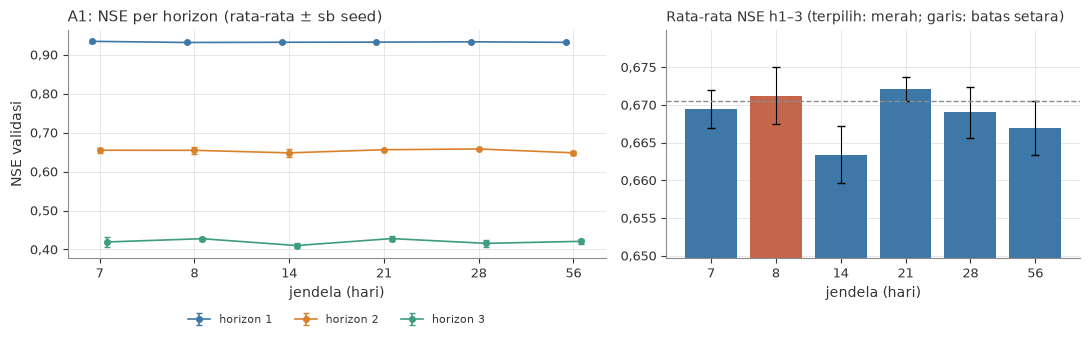

In [7]:
gambar_pilihan("A1", R_A1, tab, terpilih, "jendela (hari)")

### Hasil

- **Jendela 7, 8, dan 21 hari tidak dapat dibedakan dengan 3 seed.** Rata-rata
  NSE h1–3 ketiganya 0,670 ± 0,003, 0,671 ± 0,004, dan 0,672 ± 0,002; selisih
  terbesarnya 0,003 NSE, lebih kecil dari simpangan baku antar-seed jendela 7
  dan 8 hari. Jendela 28 hari (0,669 ± 0,003) juga hanya sedikit di bawahnya.
- **Hipotesis awal bahwa 14 hari (1,25τ) adalah jendela yang tepat tidak
  didukung validasi.** Jendela 14 hari justru terendah: 0,663 ± 0,004, atau 5,6
  simpangan baku jendela terbaik di bawah 21 hari. Penurunannya terlihat pada
  horizon 2 dan 3; horizon 1 praktis sama untuk semua jendela (0,931–0,934).
- Keenam jendela dinilai pada 1.370 tanggal target validasi yang sama untuk
  setiap horizon, termasuk jendela 56 hari, sehingga perbedaannya tidak berasal
  dari sampel validasi yang berbeda. Jendela yang lebih panjang hanya
  kehilangan beberapa sampel latih pertama (6.336 sampel latih h1 untuk 56 hari,
  6.385 untuk 7 hari).
- **Pilihan: 8 hari**, menurut aturan setara di tahap 2. Jendela terbaik adalah
  21 hari dengan simpangan baku antar-seed 0,0016, sehingga batas setaranya
  0,6706. Jendela 8 hari (0,6712) berada di atas batas itu, sedangkan jendela 7
  hari (0,6695) berada sedikit di bawahnya. Dari 8 dan 21 hari, dipilih yang
  lebih sederhana. Nilai ini sama dengan jendela Le dkk. (2025), dan satu run
  rata-rata 17 detik, dibanding 28 detik untuk 21 hari.
- Aturan setara dipakai apa adanya, walaupun hasilnya peka terhadap simpangan
  baku yang dihitung dari 3 seed: dengan simpangan baku jendela 8 hari (0,0037),
  jendela 7 dan 28 hari juga akan setara dan pilihannya menjadi 7 hari. Aturan
  ditetapkan sebelum hasil dilihat, jadi tidak diubah setelahnya.
- Jendela 56 hari (0,667 ± 0,004) tidak lebih baik daripada jendela pendek.
  Riwayat resesi yang panjang tidak menambah informasi pada pengaturan tengah.

## 4. A2 — Sumber hujan

Dasar: [Kratzert2019] untuk forcing grid rata-rata DAS (Daymet); [Le2025] memakai
hujan stasiun; [Thornton2021] untuk geser Daymet satu hari

Dua pilihan dibandingkan pada jendela hasil A1: hujan Daymet rata-rata DAS yang
digeser satu hari (pilihan dasar), dan hujan stasiun GHCN-Daily yang dipetakan
ke setiap pos dengan IDW, tanggal `.dly` tanpa koreksi jam pengamatan. Hanya
kanal hujan yang diganti; Tmax dan Tmin tetap dari Daymet.

Tampilkan dulu: kedua sumber di bagian latih, per pos.

bagian latih, jendela A1 = 8 hari; hari hujan = hujan >= 1 mm
          Daymet_mm_per_tahun  GHCN_mm_per_tahun  Daymet_hari_hujan_%  GHCN_hari_hujan_%  korelasi_harian  korelasi_geser_GHCN_-1
pos                                                                                                                              
02018000              1211.28            1055.68                36.15              34.70             0.91                    0.29
02020500              1201.25            1124.78                34.37              40.14             0.88                    0.42
02021500              1208.93            1170.31                34.32              37.81             0.88                    0.36
02022500              1241.32            1166.56                31.46              29.74             0.91                    0.18
02019500              1197.04            1139.72                38.30              36.73             0.89                    0.39
02024000              1212.1

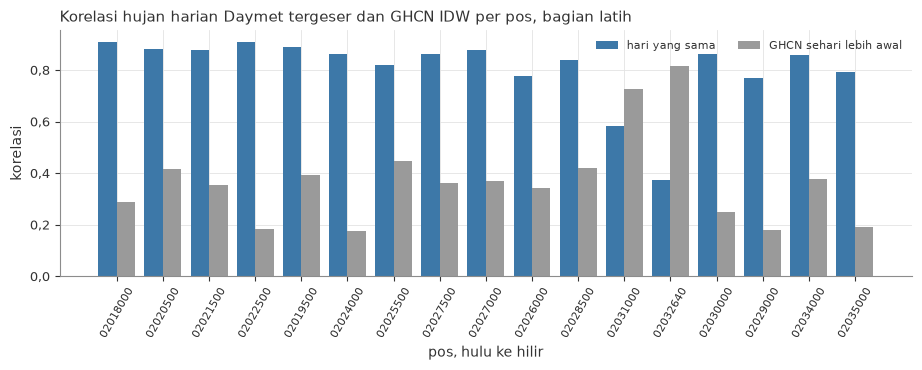

In [8]:
W_A = PILIHAN_A["A1"]
G = pm.hujan_ghcn_harian()
P_ghcn = pm.balik_log1p(G["z"][:i_val - 1], G["rata"], G["std"])
l_ = slice(0, i_latih)
banding = pd.DataFrame({
    "Daymet_mm_per_tahun": P_daymet[l_].mean(0) * 365.25, "GHCN_mm_per_tahun": P_ghcn[l_].mean(0) * 365.25,
    "Daymet_hari_hujan_%": (P_daymet[l_] >= 1).mean(0) * 100, "GHCN_hari_hujan_%": (P_ghcn[l_] >= 1).mean(0) * 100,
    "korelasi_harian": [np.corrcoef(P_daymet[l_, j], P_ghcn[l_, j])[0, 1] for j in range(P_daymet.shape[1])],
    "korelasi_geser_GHCN_-1": [np.corrcoef(P_daymet[1:i_latih, j], P_ghcn[:i_latih - 1, j])[0, 1]
                               for j in range(P_daymet.shape[1])],
}, index=pd.Index(H17["pos"], name="pos"))
print(f"bagian latih, jendela A1 = {W_A} hari; hari hujan = hujan >= 1 mm")
print(banding.round(2).to_string())

fig, ax = plt.subplots(figsize=(11, 3.2))
xp = np.arange(len(banding))
ax.bar(xp - 0.2, banding["korelasi_harian"], 0.4, color=WARNA["utama"], label="hari yang sama")
ax.bar(xp + 0.2, banding["korelasi_geser_GHCN_-1"], 0.4, color=ABU, label="GHCN sehari lebih awal")
ax.set_xticks(xp); ax.set_xticklabels(banding.index, rotation=60, fontsize=8); sumbu_koma(ax, d=1)
ax.set_ylabel("korelasi"); ax.set_xlabel("pos, hulu ke hilir"); ax.legend(ncol=2, fontsize=8)
ax.set_title("Korelasi hujan harian Daymet tergeser dan GHCN IDW per pos, bagian latih", loc="left")
simpan_gambar(fig, "tahap_A2_korelasi_daymet_ghcn")

In [9]:
t0 = time.perf_counter()
URUTAN_A2 = ["daymet", "ghcn_idw"]
latih_langkah("A2", [dict(jendela=W_A, hujan=s) for s in URUTAN_A2])
tab = pd.concat([jalankan_pilihan("A2", s, jendela=W_A, hujan=s) for s in URUTAN_A2], ignore_index=True)
HASIL_A["A2"] = tab
R_A2 = ringkas_pilihan(tab, URUTAN_A2)
terbaik, batas, setara, terpilih = pilih(R_A2, URUTAN_A2)
PILIHAN_A["A2"] = terpilih
print(f"\nwaktu: {(time.perf_counter() - t0) / 60:.1f} menit\n")
print(tampil_ringkas(R_A2).rename_axis("hujan").to_string())
print(f"\nterbaik: {terbaik}; batas setara: {koma(batas, d=4)}; setara: {', '.join(setara)}; terpilih: {terpilih}")

A2: 18 run, 0 dikerjakan dengan 2 proses dalam 0.0 menit, 18 sudah selesai sebelumnya
                  daymet: NSE h1-3 0,931, 0,655, 0,428; rata-rata 94 epoch, 17 detik per run
                ghcn_idw: NSE h1-3 0,950, 0,707, 0,465; rata-rata 89 epoch, 20 detik per run


tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

waktu: 0.0 menit

         NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
hujan                                                          
daymet    0,931  0,655  0,428  0,671 ± 0,004   0,714         94
ghcn_idw  0,950  0,707  0,465  0,707 ± 0,001   0,745         89

terbaik: ghcn_idw; batas setara: 0,7061; setara: ghcn_idw; terpilih: ghcn_idw


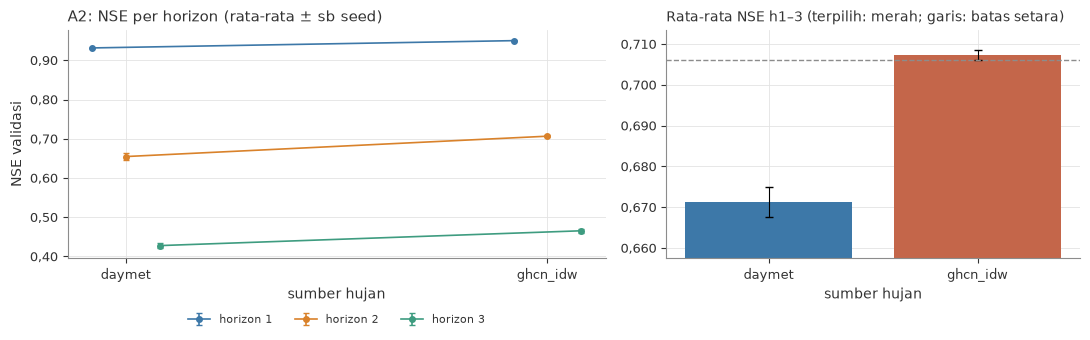

In [10]:
gambar_pilihan("A2", R_A2, tab, terpilih, "sumber hujan")

### Hasil

- **GHCN-Daily jauh lebih baik daripada Daymet tergeser.** Rata-rata NSE h1–3
  naik dari 0,671 ± 0,004 menjadi 0,707 ± 0,001. Selisih 0,036 ini sekitar 25
  kali simpangan baku antar-seed GHCN, dan terlihat di setiap horizon: 0,931 →
  0,950 pada h1, 0,655 → 0,707 pada h2, dan 0,428 → 0,465 pada h3. KGE naik dari
  0,714 menjadi 0,745. Tidak ada pilihan yang setara, jadi dipilih **GHCN
  (IDW)**.
- Kedua sumber mirip dalam jumlah hari hujan, tetapi hujan tahunan GHCN di
  bagian latih lebih rendah (1.056–1.240 mm, Daymet 1.162–1.409 mm). Korelasi
  hariannya 0,77–0,91 di sebagian besar pos. Di pos 02031000 dan 02032640
  korelasinya lebih tinggi bila GHCN digeser sehari lebih awal (0,73 dan 0,81
  dibanding 0,58 dan 0,37), karena stasiun terdekatnya stasiun COOP yang dibaca
  pagi.
- Dugaan penyebab, belum diuji: kanal Daymet tergeser pada hari t mencakup hujan
  sampai sekitar pukul 07.00 hari t, sedangkan tiga stasiun bandara GHCN
  (Roanoke, Lynchburg, Charlottesville) mencatat hujan sampai tengah malam hari t.
  GHCN membawa hujan sore dan malam hari t. Informasi itu sudah tersedia pada
  akhir hari t, sama dengan debit rata-rata hari t, jadi tidak memuat hujan hari
  target. Dugaan ini bisa diuji dengan ablasi stasiun bandara.
- Jendela 8 hari dipilih di A1 dengan hujan Daymet. Sesuai desain tahap A yang
  berurutan, jendela tidak diuji ulang dengan GHCN.

## 5. A3 — Transformasi hujan

Dasar: [Feng2020] untuk log10(√x + 0,1) pada hujan berdistribusi Gamma; log1p:
pilihan preprocessing tahap 26

Kedua transformasi diikuti standardisasi per pos dengan rata-rata dan simpangan
baku bagian latih. Tampilkan dulu: bentuk sebaran hujan pos target di bagian
latih setelah tiap transformasi.

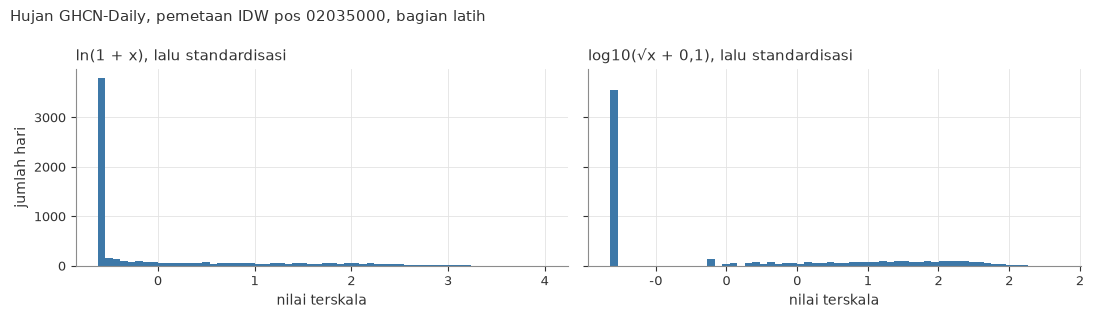

ln(1 + x)       : skewness 1.53; hari kering -0.62; hujan 1 mm 0.06; maksimum 4.01
log10(√x + 0,1) : skewness 0.63; hari kering -0.82; hujan 1 mm 0.80; maksimum 2.35


In [11]:
H_A = PILIHAN_A["A2"]
P_a = P_daymet if H_A == "daymet" else P_ghcn
it = H17["i_target"]
FUNGSI = {"log1p": np.log1p, "log10_akar": lambda x: np.log10(np.sqrt(x) + 0.1)}
Z, SK = {}, {}
for t in FUNGSI:
    z_, r_, s_ = pm.skala_hujan(P_a, t)
    Z[t], SK[t] = z_[:i_latih], (r_[it], s_[it])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a_, (t, z_) in zip(ax, Z.items()):
    a_.hist(z_[:, it], bins=60, color=WARNA["utama"])
    a_.set_title(f"{pm.TRANSFORMASI[t]}, lalu standardisasi", loc="left"); a_.set_xlabel("nilai terskala"); sumbu_koma(a_, "x", d=0)
ax[0].set_ylabel("jumlah hari")
fig.suptitle(f"Hujan {pm.HUJAN[H_A]} pos {TARGET}, bagian latih", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
simpan_gambar(fig, "tahap_A3_sebaran_transformasi")
for t, z_ in Z.items():
    r_, s_ = SK[t]
    kering, satu_mm = (FUNGSI[t](0.0) - r_) / s_, (FUNGSI[t](1.0) - r_) / s_
    print(f"{pm.TRANSFORMASI[t]:16}: skewness {pd.Series(z_[:, it]).skew():.2f}; hari kering {kering:.2f}; "
          f"hujan 1 mm {satu_mm:.2f}; maksimum {z_[:, it].max():.2f}")

In [12]:
t0 = time.perf_counter()
URUTAN_A3 = ["log1p", "log10_akar"]
latih_langkah("A3", [dict(jendela=W_A, hujan=H_A, transformasi=t) for t in URUTAN_A3])
tab = pd.concat([jalankan_pilihan("A3", t, jendela=W_A, hujan=H_A, transformasi=t) for t in URUTAN_A3],
                ignore_index=True)
HASIL_A["A3"] = tab
R_A3 = ringkas_pilihan(tab, URUTAN_A3)
terbaik, batas, setara, terpilih = pilih(R_A3, URUTAN_A3)
PILIHAN_A["A3"] = terpilih
print(f"\nwaktu: {(time.perf_counter() - t0) / 60:.1f} menit\n")
print(tampil_ringkas(R_A3).rename_axis("transformasi").to_string())
print(f"\nterbaik: {terbaik}; batas setara: {koma(batas, d=4)}; setara: {', '.join(setara)}; terpilih: {terpilih}")

A3: 18 run, 0 dikerjakan dengan 2 proses dalam 0.0 menit, 18 sudah selesai sebelumnya
                   log1p: NSE h1-3 0,950, 0,707, 0,465; rata-rata 89 epoch, 20 detik per run


              log10_akar: NSE h1-3 0,943, 0,691, 0,465; rata-rata 85 epoch, 19 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

waktu: 0.0 menit

             NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
transformasi                                                       
log1p         0,950  0,707  0,465  0,707 ± 0,001   0,745         89
log10_akar    0,943  0,691  0,465  0,699 ± 0,002   0,740         85

terbaik: log1p; batas setara: 0,7061; setara: log1p; terpilih: log1p


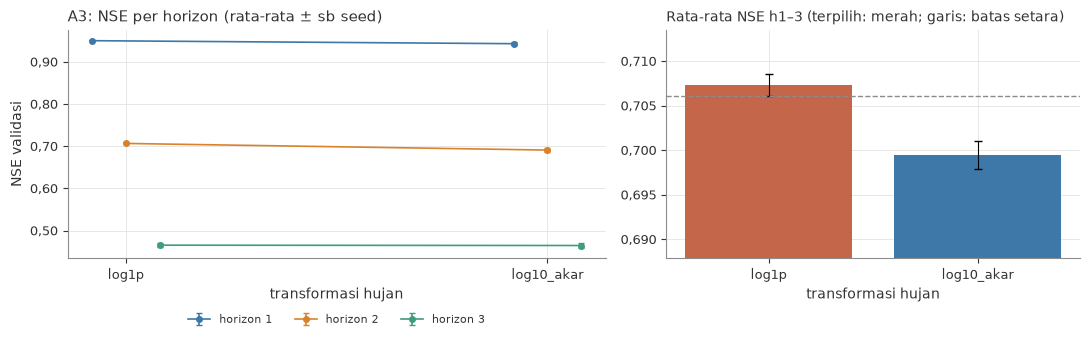

In [13]:
gambar_pilihan("A3", R_A3, tab, terpilih, "transformasi hujan")

### Hasil

- **log1p lebih baik daripada log10(√x + 0,1)**: 0,707 ± 0,001 dibanding
  0,699 ± 0,002. Selisihnya ada pada horizon 1 (0,950 dan 0,943) dan horizon 2
  (0,707 dan 0,691); horizon 3 sama (0,465). log1p adalah pilihan terbaik
  sekaligus yang lebih sederhana, jadi dipilih **log1p**.
- Transformasi Feng2020 membuat sebaran hujan pos target lebih simetris
  (skewness 0,63 dibanding 1,53) dan memisahkan hari kering dari hujan 1 mm
  lebih lebar (1,62 dibanding 0,68 satuan terskala). Pemisahan yang lebih lebar
  untuk hujan kecil itu tidak membantu prediksi debit di DAS ini.

## 6. A4 — Varian pos

Dasar: aturan seleksi pos preprocessing (tahap 1 dan 28): V17 adalah pos dengan
rekaman sejak awal bagian latih; V18 menambah Harris Creek; V21 menambah empat
pos yang mulai merekam terlambat dan awalnya diisi MOVE.1; pemetaan hujan GHCN
untuk pos tambahan: fungsi `petakan_idw` preprocessing tahap 17b

Bila A2 memilih GHCN, pos tambahan V18 dan V21 belum punya kanal hujan GHCN di
`processed/`. Kanalnya dipetakan dengan `petakan_idw` dan `jarak_km` yang disalin
apa adanya dari preprocessing (radius 50 km, bobot 1/d²), dari input stasiun yang
sama (`processed/hujan/hujan_harian_mm.csv`) dan koordinat pos di
`raw/sites/site_info.rdb`. Pemeriksaannya: pemetaan ulang untuk 17 pos V17 harus
identik dengan kanal GHCN di tensor.

Tampilkan dulu: pos tambahan, jumlah nilai isian tiap varian, dan pemetaan hujan
untuk pos tambahan.

In [14]:
T_A = PILIHAN_A["A3"]
v17 = pm.META["varian"]["V17"]["pos"]
for v in ["V17", "V18", "V21"]:
    info = pm.META["varian"][v]
    tambahan = [q for q in info["pos"] if q not in v17]
    print(f"{v}: {len(info['pos'])} pos, nilai isian {ribu(info['nilai_isian'])}; tambahan: {', '.join(tambahan) or '—'}")
catatan = pd.DataFrame(pm.META["aturan_isian"]["catatan"])
print()
print(catatan[catatan["pos"].isin(set(pm.META["varian"]["V21"]["pos"]) - set(v17))]
      [["pos", "jenis", "metode", "hari", "bagian", "donor", "keterangan"]].to_string(index=False))

if H_A == "ghcn_idw":
    P17, _, _ = pm.ghcn_idw_mm(v17)
    P17 = np.r_[P17.to_numpy(float)[:i_val - 1], np.full((n_hari - i_val + 1, len(v17)), np.nan)]
    z17 = pm.skala_hujan(P17, "log1p")[0][:i_val - 1].astype(np.float32)
    assert np.array_equal(z17, G["z"][:i_val - 1])
    print("\npemetaan IDW ulang untuk 17 pos V17 identik (float32) dengan kanal GHCN di tensor")
    tambahan = [q for q in pm.META["varian"]["V21"]["pos"] if q not in v17]
    P_t, cad_t, D_t = pm.ghcn_idw_mm(tambahan)
    print(pd.DataFrame({"stasiun_dalam_50km": (D_t <= pm.R_IDW).sum(axis=1), "stasiun_terdekat_km": D_t.min(axis=1).round(1),
                        "hari_cadangan": cad_t.sum(), "hujan_latih_mm_per_tahun": P_t.iloc[:i_latih].mean() * 365.25})
          .round(1).rename_axis("pos tambahan").to_string())

V17: 17 pos, nilai isian 127; tambahan: —
V18: 18 pos, nilai isian 4.550; tambahan: 02025652
V21: 21 pos, nilai isian 7.283; tambahan: 02024915, 02024752, 02032250, 02030500

     pos        jenis metode  hari bagian    donor                                             keterangan
02024752 awal rekaman MOVE.1  2100  latih 02025500 fit 4,291 hari; NSE log latih 0,99, sesudah latih 0,99
02024915 awal rekaman MOVE.1  1042  latih 02027000 fit 5,350 hari; NSE log latih 0,88, sesudah latih 0,88
02030500 awal rekaman MOVE.1  2000  latih 02030000 fit 4,392 hari; NSE log latih 0,84, sesudah latih 0,72
02032250 awal rekaman MOVE.1  2014  latih 02031000 fit 4,378 hari; NSE log latih 0,89, sesudah latih 0,87



pemetaan IDW ulang untuk 17 pos V17 identik (float32) dengan kanal GHCN di tensor
              stasiun_dalam_50km  stasiun_terdekat_km  hari_cadangan  hujan_latih_mm_per_tahun
pos tambahan                                                                                  
02024915                       2                 16.4              0                    1214.0
02024752                       3                  9.2              0                    1218.5
02032250                       5                  8.8              0                    1061.6
02030500                       4                  4.9              0                    1078.0


In [15]:
t0 = time.perf_counter()
URUTAN_A4 = ["V17", "V18", "V21"]
latih_langkah("A4", [dict(varian=v, jendela=W_A, hujan=H_A, transformasi=T_A) for v in URUTAN_A4])
tab = pd.concat([jalankan_pilihan("A4", v, varian=v, jendela=W_A, hujan=H_A, transformasi=T_A) for v in URUTAN_A4],
                ignore_index=True)
HASIL_A["A4"] = tab
R_A4 = ringkas_pilihan(tab, URUTAN_A4)
terbaik, batas, setara, terpilih = pilih(R_A4, URUTAN_A4)
PILIHAN_A["A4"] = terpilih
print(f"\nwaktu: {(time.perf_counter() - t0) / 60:.1f} menit\n")
print(tampil_ringkas(R_A4).rename_axis("varian").to_string())
print(f"\nterbaik: {terbaik}; batas setara: {koma(batas, d=4)}; setara: {', '.join(setara)}; terpilih: {terpilih}")

A4: 27 run, 0 dikerjakan dengan 2 proses dalam 0.0 menit, 27 sudah selesai sebelumnya
                     V17: NSE h1-3 0,950, 0,707, 0,465; rata-rata 89 epoch, 20 detik per run


                     V18: NSE h1-3 0,942, 0,701, 0,462; rata-rata 68 epoch, 16 detik per run


                     V21: NSE h1-3 0,957, 0,700, 0,458; rata-rata 88 epoch, 21 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

waktu: 0.0 menit

       NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
varian                                                       
V17     0,950  0,707  0,465  0,707 ± 0,001   0,745         89
V18     0,942  0,701  0,462  0,702 ± 0,004   0,734         68
V21     0,957  0,700  0,458  0,705 ± 0,002   0,739         88

terbaik: V17; batas setara: 0,7061; setara: V17; terpilih: V17


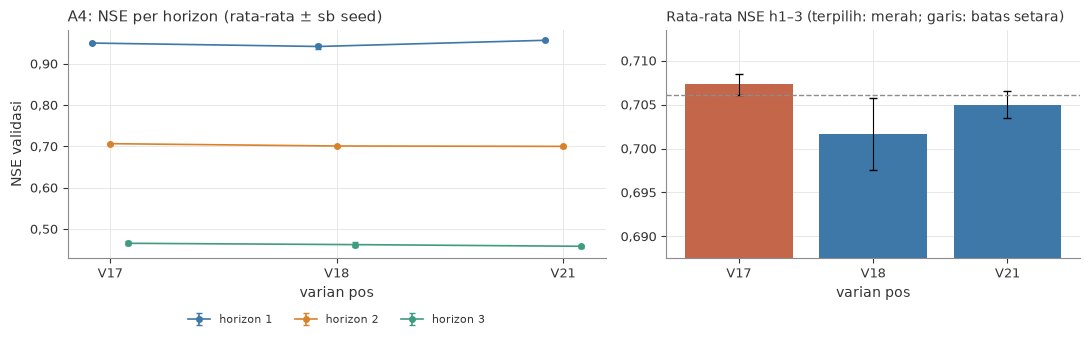

In [16]:
gambar_pilihan("A4", R_A4, tab, terpilih, "varian pos")

### Hasil

- **V17 tetap terbaik**: 0,707 ± 0,001. V21 (0,705 ± 0,002) dan V18
  (0,702 ± 0,004) berada di bawah batas setara 0,7061, jadi dipilih **V17**,
  yang juga paling sederhana. Hasil ini sesuai dengan dugaan preprocessing bahwa
  V21 tidak lebih baik daripada V17.
- V21 memberi NSE horizon 1 tertinggi di seluruh tahap A (0,957), tetapi lebih
  rendah pada horizon 2 dan 3 (0,700 dan 0,458). Empat pos tambahannya sebagian
  besar berisi nilai isian MOVE.1 di awal bagian latih (1.042–2.100 hari).
- V18 berhenti lebih awal (rata-rata 68 epoch dibanding 89) dan paling rendah.
  Harris Creek (02025652) diisi MOVE.1 selama 4.422 hari dengan NSE log sesudah
  latih 0,73.
- Hujan GHCN untuk lima pos tambahan dipetakan dengan `petakan_idw`
  preprocessing. Pemetaan ulang untuk 17 pos V17 identik dengan tensor; setiap
  pos tambahan punya 2–5 stasiun dalam radius 50 km dan tidak memakai stasiun
  cadangan.

## 7. Ringkasan tahap A

Dasar: deskriptif, tidak ada keputusan metodologis

Pilihan yang terkunci dipakai di tahap B. Tabel per run disimpan ke
`modeling/hasil/tahap_a_per_run.csv`, ringkasan per pilihan ke
`modeling/hasil/tahap_a_ringkasan.csv`, dan pilihan terkunci ke
`modeling/hasil/pilihan_tahap_a.json`.

In [17]:
ringkas_semua = pd.concat({k: r for k, r in [("A1", R_A1), ("A2", R_A2), ("A3", R_A3), ("A4", R_A4)]},
                          names=["langkah", "pilihan"])
pd.concat(HASIL_A.values(), ignore_index=True).to_csv(HASIL / "tahap_a_per_run.csv", index=False)
ringkas_semua.round(5).to_csv(HASIL / "tahap_a_ringkasan.csv")
kunci = {"jendela": PILIHAN_A["A1"], "hujan": PILIHAN_A["A2"], "transformasi": PILIHAN_A["A3"], "varian": PILIHAN_A["A4"],
         "mesin": pm.mesin(), "kriteria": ("rata-rata NSE validasi h1-3 atas 3 seed; setara bila NSE >= NSE terbaik - sb antar-seed konfigurasi "
                      "terbaik; di antara yang setara dipilih yang paling sederhana")}
(HASIL / "pilihan_tahap_a.json").write_text(json.dumps(kunci, indent=2, ensure_ascii=False))
print(json.dumps(kunci, indent=2, ensure_ascii=False))
print()
print(tampil_ringkas(ringkas_semua).to_string())

{
  "jendela": 8,
  "hujan": "ghcn_idw",
  "transformasi": "log1p",
  "varian": "V17",
  "mesin": "x86_64-NVIDIA GeForce RTX 4060",
  "kriteria": "rata-rata NSE validasi h1-3 atas 3 seed; setara bila NSE >= NSE terbaik - sb antar-seed konfigurasi terbaik; di antara yang setara dipilih yang paling sederhana"
}

                   NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
langkah pilihan                                                          
A1      7           0,934  0,655  0,419  0,670 ± 0,003   0,707        100
        8           0,931  0,655  0,428  0,671 ± 0,004   0,714         94
        14          0,932  0,648  0,410  0,663 ± 0,004   0,689         92
        21          0,932  0,656  0,428  0,672 ± 0,002   0,711        100
        28          0,933  0,658  0,416  0,669 ± 0,003   0,709         91
        56          0,932  0,648  0,421  0,667 ± 0,004   0,699        100
A2      daymet      0,931  0,655  0,428  0,671 ± 0,004   0,714         94
        ghcn_idw    0,

### Hasil

| Faktor | Terkunci | NSE h1–3 pilihan terkunci | Pilihan dasar |
|---|---|---|---|
| Jendela (A1) | 8 hari | 0,671 ± 0,004 | 14 hari: 0,663 ± 0,004 |
| Sumber hujan (A2) | GHCN-Daily, IDW | 0,707 ± 0,001 | Daymet tergeser: 0,671 ± 0,004 |
| Transformasi hujan (A3) | log1p | 0,707 ± 0,001 | sama |
| Varian pos (A4) | V17 | 0,707 ± 0,001 | sama |

- Dengan pengaturan tengah CNN-LSTM, tahap A menaikkan rata-rata NSE h1–3 dari
  0,663 ± 0,004 (pilihan dasar) menjadi 0,707 ± 0,001. Sebagian besar kenaikan
  datang dari sumber hujan (0,036); jendela menyumbang 0,008.
- Dua pilihan dasar preprocessing tidak didukung validasi: jendela 14 hari dan
  hujan Daymet. Transformasi log1p dan varian V17 tetap.
- Semua pilihan di setiap langkah dinilai pada 1.370 tanggal target validasi yang
  sama per horizon. Bagian uji tidak dimuat.
- Tahap B memakai V17, jendela 8 hari, hujan GHCN IDW, dan log1p untuk ketiga
  jaringan.

## 8. Cek ulang A1 dengan hujan GHCN

Dasar: deskriptif; laporan saja, tidak mengubah pilihan tahap A

A1 dikunci saat kanal hujan masih Daymet. Karena A2 kemudian memilih GHCN,
keenam jendela diuji ulang dengan GHCN (IDW), log1p, dan V17. Hasilnya tidak
mengubah pilihan. Kalau ada jendela yang NSE-nya berada di atas batas setara
jendela 8 hari (NSE jendela 8 + simpangan baku antar-seed jendela 8), atau
jendela 8 tidak lagi setara dengan jendela terbaik menurut aturan tahap 2,
pekerjaan dihentikan dan dilaporkan sebelum tahap B.

In [18]:
NAMA_LANGKAH["A1_ghcn"] = "jendela_ghcn"
latih_langkah("A1_ghcn", [dict(jendela=w, hujan="ghcn_idw") for w in JENDELA])
tab = pd.concat([jalankan_pilihan("A1_ghcn", f"{w}", jendela=w, hujan="ghcn_idw") for w in JENDELA], ignore_index=True)
HASIL_A["A1_ghcn"] = tab
R_A1g = ringkas_pilihan(tab, URUTAN_A1)
terbaik, batas, setara, terpilih_g = pilih(R_A1g, URUTAN_A1)
atas_8 = R_A1g.loc["8", "NSE_h13"] + R_A1g.loc["8", "sb"]
di_atas = [w for w in URUTAN_A1 if w != "8" and R_A1g.loc[w, "NSE_h13"] > atas_8]
print()
print(tampil_ringkas(R_A1g).rename_axis("jendela").to_string())
print(f"\nbatas atas setara jendela 8 (NSE + sb): {koma(atas_8, d=4)}; jendela di atasnya: {', '.join(di_atas) or 'tidak ada'}")
print(f"aturan tahap 2: terbaik {terbaik} hari, batas setara {koma(batas, d=4)}, setara: {', '.join(setara)}; "
      f"jendela 8 setara: {'8' in setara}")
CEK_A1_LULUS = not di_atas and "8" in setara
print(f"cek ulang A1 lulus: {CEK_A1_LULUS}")

A1_ghcn: 54 run, 0 dikerjakan dengan 2 proses dalam 0.0 menit, 54 sudah selesai sebelumnya


                       7: NSE h1-3 0,951, 0,700, 0,456; rata-rata 82 epoch, 19 detik per run
                       8: NSE h1-3 0,950, 0,707, 0,465; rata-rata 89 epoch, 20 detik per run


                      14: NSE h1-3 0,953, 0,699, 0,453; rata-rata 82 epoch, 22 detik per run


                      21: NSE h1-3 0,949, 0,703, 0,469; rata-rata 86 epoch, 30 detik per run


                      28: NSE h1-3 0,952, 0,706, 0,459; rata-rata 78 epoch, 35 detik per run


                      56: NSE h1-3 0,950, 0,693, 0,457; rata-rata 84 epoch, 70 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

        NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
jendela                                                       
7        0,951  0,700  0,456  0,702 ± 0,003   0,739         82
8        0,950  0,707  0,465  0,707 ± 0,001   0,745         89
14       0,953  0,699  0,453  0,701 ± 0,004   0,727         82
21       0,949  0,703  0,469  0,707 ± 0,003   0,739         86
28       0,952  0,706  0,459  0,705 ± 0,001   0,745         78
56       0,950  0,693  0,457  0,700 ± 0,007   0,733         84

batas atas setara jendela 8 (NSE + sb): 0,7085; jendela di atasnya: tidak ada
aturan tahap 2: terbaik 8 hari, batas setara 0,7061, setara: 8, 21; jendela 8 setara: True
cek ulang A1 lulus: True


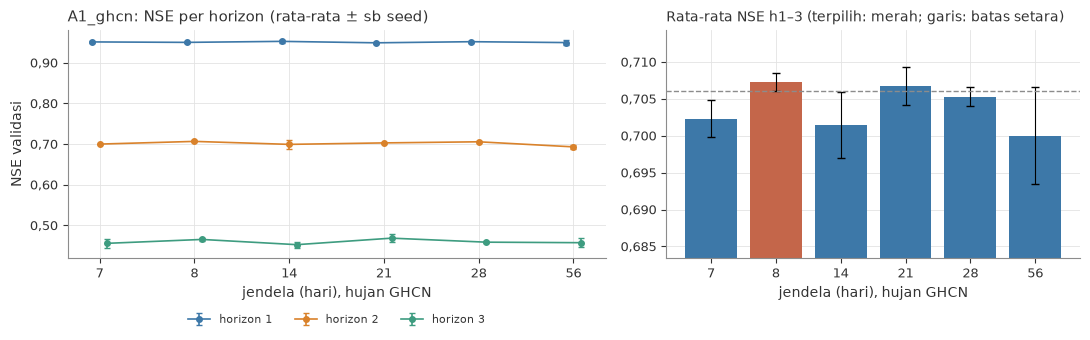

In [19]:
gambar_pilihan("A1_ghcn", R_A1g, tab, "8", "jendela (hari), hujan GHCN")

### Hasil

- Dengan hujan GHCN, **jendela 8 hari menjadi yang terbaik**: 0,707 ± 0,001.
  Jendela 21 hari setara (0,707 ± 0,003); 28 hari 0,705 ± 0,001, 7 hari
  0,702 ± 0,003, 14 hari 0,701 ± 0,004, dan 56 hari 0,700 ± 0,007.
- Tidak ada jendela di atas batas setara jendela 8 hari (0,7085), dan jendela 8
  hari setara dengan jendela terbaik menurut aturan tahap 2. Pilihan A1 tetap,
  dan pekerjaan dilanjutkan.
- Seperti dengan Daymet, horizon 1 hampir sama untuk semua jendela
  (0,949–0,953); perbedaannya datang dari horizon 2 dan 3.

## 9. Sensitivitas hujan GHCN

Dasar: preprocessing tahap 17b untuk pemetaan stasiun terdekat dan IDW; radius 30
dan 80 km serta ablasi stasiun bandara: pilihan sendiri, untuk menguji dugaan di
A2; laporan saja, tidak mengubah pilihan tahap A

**Waktu pengamatan GHCN.** Input GHCN memakai tanggal file `.dly`, yaitu akhir
periode pengamatan. Stasiun COOP yang dibaca pagi mencatat hujan 24 jam yang
berakhir pada pembacaan pagi tanggal t; stasiun bandara mencatat hari kalender t,
dari tengah malam ke tengah malam. Dalam kedua kasus, nilai tanggal t hanya
memuat hujan sampai paling lambat akhir hari t, sehingga tidak memuat informasi
hari target t + h (h ≥ 1).

Pilihan yang diuji, semua dengan V17, jendela 8 hari, dan log1p:

| Pilihan | Pemetaan |
|---|---|
| IDW 30 km, IDW 50 km (terkunci), IDW 80 km | `petakan_idw`, bobot 1/d², radius berbeda |
| terdekat | `petakan_terdekat`: stasiun terdekat, hari kosong dari stasiun terdekat berikutnya |
| IDW 50 km tanpa bandara | IDW 50 km setelah stasiun Roanoke, Lynchburg, dan Charlottesville dikeluarkan |
| Daymet tergeser | pembanding dari A2 |

Kalau keunggulan GHCN berasal dari hujan sore dan malam hari t yang dicatat
stasiun bandara, NSE tanpa bandara akan turun mendekati Daymet.

Tampilkan dulu: stasiun yang dipakai tiap pemetaan. Pemetaan terdekat dihitung
ulang dan dibandingkan dengan `X_terdekat` di `tensor_hujan_h1.npz`.

In [20]:
PILIHAN_S = {"Daymet": "daymet", "IDW 30 km": "ghcn_idw30", "IDW 50 km": "ghcn_idw", "IDW 80 km": "ghcn_idw80",
             "terdekat": "ghcn_terdekat", "IDW 50 tanpa bandara": "ghcn_idw_tanpa_bandara"}
v17 = pm.META["varian"]["V17"]["pos"]
baris = []
for label, kode in PILIHAN_S.items():
    if kode == "daymet":
        continue
    metode, radius, kecuali = pm.PEMETAAN_GHCN[kode]
    P_, cad_, D_ = pm.ghcn_idw_mm(v17, metode, radius or pm.R_IDW, kecuali)
    n_dalam = (D_ <= (radius or 0)).sum(axis=1) if metode == "idw" else pd.Series(1, index=D_.index)
    baris.append({"pemetaan": label, "stasiun": D_.shape[1],
                  "stasiun_per_pos_min": int(n_dalam.min()), "stasiun_per_pos_maks": int(n_dalam.max()),
                  "pos_tanpa_stasiun_dalam_radius": int((n_dalam == 0).sum()),
                  "sel_cadangan_%": round(float(cad_.to_numpy().mean() * 100), 2),
                  "hujan_latih_mm_per_tahun": round(float(P_.iloc[:i_latih].mean().mean() * 365.25)),
                  "korelasi_dengan_IDW50_pos_target": round(float(np.corrcoef(P_.iloc[:i_latih][TARGET],
                                                              P_ghcn[:i_latih, H17["i_target"]])[0, 1]), 3)})
    if kode == "ghcn_terdekat":
        z_t = pm.skala_hujan(np.r_[P_.to_numpy(float)[:i_val - 1], np.full((n_hari - i_val + 1, 17), np.nan)], "log1p")[0]
        X_t, _, idx_t = pm._jendela_latih_val(pm.PROC / "tensor_hujan_h1.npz", "X_terdekat")
        assert np.array_equal(z_t[:i_val - 1].astype(np.float32), pm._harian_dari_jendela(X_t, idx_t, 1)[:i_val - 1, :, 0])
print("pemetaan terdekat yang dihitung ulang identik (float32) dengan X_terdekat di tensor_hujan_h1.npz")
print("stasiun bandara:", ", ".join(pm.BANDARA))
print(pd.DataFrame(baris).set_index("pemetaan").to_string())

pemetaan terdekat yang dihitung ulang identik (float32) dengan X_terdekat di tensor_hujan_h1.npz
stasiun bandara: USW00013741, USW00013733, USW00093736
                      stasiun  stasiun_per_pos_min  stasiun_per_pos_maks  pos_tanpa_stasiun_dalam_radius  sel_cadangan_%  hujan_latih_mm_per_tahun  korelasi_dengan_IDW50_pos_target
pemetaan                                                                                                                                                                            
IDW 30 km                  16                    0                     2                               5           30.11                      1146                             0.992
IDW 50 km                  16                    1                     5                               0            0.00                      1116                             1.000
IDW 80 km                  16                    5                    10                               0            0.00    

In [21]:
NAMA_LANGKAH["S_ghcn"] = "sensitivitas_ghcn"
latih_langkah("S_ghcn", [dict(jendela=8, hujan=k) for k in PILIHAN_S.values()])
tab = pd.concat([jalankan_pilihan("S_ghcn", lab, jendela=8, hujan=k) for lab, k in PILIHAN_S.items()], ignore_index=True)
HASIL_A["S_ghcn"] = tab
R_S = ringkas_pilihan(tab, list(PILIHAN_S))
print()
print(tampil_ringkas(R_S).rename_axis("hujan").to_string())
ref = R_S.loc["IDW 50 km"]
print(f"\nselisih terhadap IDW 50 km (dalam sb antar-seed IDW 50 km = {koma(ref['sb'], d=4)}):")
for lab in R_S.index:
    print(f"  {lab:>22}: {R_S.loc[lab, 'NSE_h13'] - ref['NSE_h13']:+.4f} ({(R_S.loc[lab, 'NSE_h13'] - ref['NSE_h13']) / ref['sb']:+.1f} sb)")

S_ghcn: 54 run, 0 dikerjakan dengan 2 proses dalam 0.0 menit, 54 sudah selesai sebelumnya
                  Daymet: NSE h1-3 0,931, 0,655, 0,428; rata-rata 94 epoch, 17 detik per run


               IDW 30 km: NSE h1-3 0,947, 0,696, 0,451; rata-rata 77 epoch, 18 detik per run
               IDW 50 km: NSE h1-3 0,950, 0,707, 0,465; rata-rata 89 epoch, 20 detik per run


               IDW 80 km: NSE h1-3 0,947, 0,691, 0,459; rata-rata 79 epoch, 18 detik per run


                terdekat: NSE h1-3 0,939, 0,682, 0,444; rata-rata 84 epoch, 19 detik per run


    IDW 50 tanpa bandara: NSE h1-3 0,931, 0,659, 0,439; rata-rata 85 epoch, 19 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

                     NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
hujan                                                                      
Daymet                0,931  0,655  0,428  0,671 ± 0,004   0,714         94
IDW 30 km             0,947  0,696  0,451  0,698 ± 0,003   0,733         77
IDW 50 km             0,950  0,707  0,465  0,707 ± 0,001   0,745         89
IDW 80 km             0,947  0,691  0,459  0,699 ± 0,000   0,733         79
terdekat              0,939  0,682  0,444  0,688 ± 0,002   0,729         84
IDW 50 tanpa bandara  0,931  0,659  0,439  0,676 ± 0,002   0,721         85

selisih terhadap IDW 50 km (dalam sb antar-seed IDW 50 km = 0,0012):
                  Daymet: -0.0361 (-30.1 sb)
               IDW 30 km: -0.0096 (-8.0 sb)
               IDW 50 km: +0.0000 (+0.0 sb

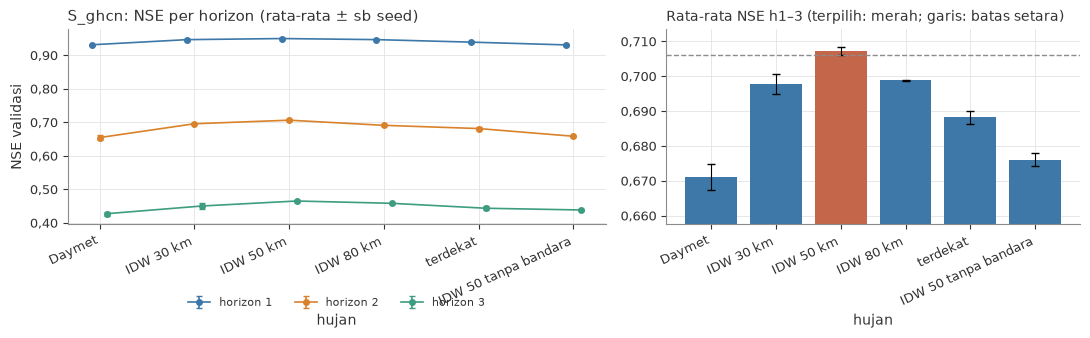

In [22]:
gambar_pilihan("S_ghcn", R_S, tab, "IDW 50 km", "hujan", rotasi=25)

### Hasil

- **IDW 50 km (pilihan terkunci) tetap terbaik**: 0,707 ± 0,001. Radius 30 km
  (0,698) dan 80 km (0,699) sama-sama lebih rendah. Pada 30 km, 5 pos tidak
  punya stasiun dalam radius, sehingga 30% sel memakai stasiun terdekat
  sebagai cadangan; pada 80 km, hujan lokal lebih banyak diratakan. Pemetaan
  stasiun terdekat lebih rendah lagi (0,688).
- **Tanpa tiga stasiun bandara, NSE turun ke 0,676 ± 0,002**, hanya 0,005 di
  atas Daymet tergeser (0,671). Hampir seluruh keunggulan GHCN atas Daymet
  (0,036) hilang ketika tiga stasiun itu dikeluarkan, walaupun setiap pos tetap
  punya sedikitnya satu stasiun dalam radius 50 km.
- Hasil ini sesuai dengan dugaan di A2: stasiun bandara mencatat hari kalender
  sampai tengah malam, sehingga kanal hujan hari t memuat hujan sore dan malam
  hari t, yang tidak ada di kanal Daymet tergeser maupun di stasiun COOP yang
  dibaca pagi. Namun ablasi ini belum memisahkan jam pengamatan dari faktor lain
  stasiun bandara, misalnya mutu alat atau letaknya. Kedua penjelasan tetap
  memakai informasi yang sudah tersedia pada akhir hari t.

## 10. Pembanding pada konfigurasi data tahap A

Dasar: metode yang sama dengan notebook 01 tahap 3–9; deskriptif

Supaya pembanding setara dengan CNN-LSTM, model pembanding dihitung ulang pada
konfigurasi data tahap A (V17, jendela 8 hari, hujan GHCN IDW, log1p):

- Klimatologi, persistensi, dan ARIMA hanya memakai debit pos target, jadi
  hasilnya tidak bergantung pada konfigurasi data dan diambil dari notebook 01.
  Persistensi dihitung ulang sebagai pemeriksaan.
- Regresi linear memakai semua kanal hari t, termasuk kanal hujan, sehingga
  dihitung ulang dengan cara yang sama (kuadrat terkecil, 170 fitur + intersep).
- LSTM target dan S_LSTM dilatih ulang pada pengaturan tengah, 3 seed.
- CNN-LSTM diambil dari run A4 (V17), yang memakai konfigurasi yang sama.

Hasilnya disimpan ke `modeling/hasil/baseline_validasi_tahap_a.csv`.

In [23]:
KONF_A = dict(varian=PILIHAN_A["A4"], jendela=PILIHAN_A["A1"], hujan=PILIHAN_A["A2"], transformasi=PILIHAN_A["A3"])
DATA_A = {h: data_pilihan(h, **KONF_A) for h in HORIZON}
lama = pd.read_csv(HASIL / "baseline_validasi_per_run.csv")
HASIL_P = []
for nama in ["klimatologi", "persistensi", "ARIMA"]:
    for _, b in lama[lama["model"] == nama].iterrows():
        HASIL_P.append({"model": nama, "horizon": int(b["horizon"]), "seed": np.nan,
                        **{k: float(b[k]) for k in ["NSE", "KGE", "RMSE", "MAE"]}})
for h, D in DATA_A.items():
    pers = metrik(ke_m3s(D["y_val"], D), ke_m3s(D["X_val"][:, -1, D["i_target"], 0], D))
    b = lama[(lama["model"] == "persistensi") & (lama["horizon"] == h)].iloc[0]
    assert abs(pers["NSE"] - b["NSE"]) < 1e-4, "persistensi berbeda dengan notebook 01"
    F_l = D["X_latih"][:, -1].reshape(len(D["X_latih"]), -1)
    F_v = D["X_val"][:, -1].reshape(len(D["X_val"]), -1)
    koef, *_ = np.linalg.lstsq(np.c_[np.ones(len(F_l)), F_l], D["y_latih"].astype(float), rcond=None)
    HASIL_P.append({"model": "regresi linear", "horizon": h, "seed": np.nan,
                    **metrik(ke_m3s(D["y_val"], D), ke_m3s(np.c_[np.ones(len(F_v)), F_v] @ koef, D))})
print("persistensi pada konfigurasi tahap A sama dengan notebook 01")

latih_langkah("pembanding_A", [dict(model=m_, **KONF_A) for m_ in ["lstm_target", "s_lstm"]])
NAMA_MODEL = {"lstm_target": "LSTM target", "s_lstm": "S_LSTM ala Le", "cnn_lstm": "CNN-LSTM"}
for m_ in ["lstm_target", "s_lstm", "cnn_lstm"]:
    t_ = jalankan_pilihan("pembanding_A", NAMA_MODEL[m_], model=m_, **KONF_A)
    HASIL_P += t_[["horizon", "seed", "NSE", "KGE", "RMSE", "MAE"]].assign(model=NAMA_MODEL[m_]).to_dict("records")
HASIL_P = pd.DataFrame(HASIL_P)

URUTAN_P = ["klimatologi", "persistensi", "ARIMA", "regresi linear", "LSTM target", "S_LSTM ala Le", "CNN-LSTM"]
rata_p = HASIL_P.groupby(["model", "horizon"])[["NSE", "KGE"]].mean()
sb_p = HASIL_P.groupby(["model", "horizon"])[["NSE", "KGE"]].std(ddof=1)
nse_seed = HASIL_P.assign(seed=HASIL_P["seed"].fillna(-1)).groupby(["model", "seed"])["NSE"].mean()
krit_p = nse_seed.groupby("model").agg(["mean", "std"])
lama_ring = pd.read_csv(HASIL / "baseline_validasi.csv", index_col=0)
TAB_P = pd.DataFrame(index=pd.Index(URUTAN_P, name="model"))
for h in HORIZON:
    TAB_P[f"NSE_h{h}"] = [rata_p.loc[(m_, h), "NSE"] for m_ in URUTAN_P]
TAB_P["NSE_h1-3"] = krit_p.loc[URUTAN_P, "mean"].to_numpy()
TAB_P["sb_NSE_h1-3"] = krit_p.loc[URUTAN_P, "std"].to_numpy()
TAB_P["NSE_h1-3_notebook01"] = lama_ring.loc[URUTAN_P, "NSE_h1-3"].to_numpy()
TAB_P.round(4).to_csv(HASIL / "baseline_validasi_tahap_a.csv")
HASIL_P.round(5).to_csv(HASIL / "baseline_validasi_tahap_a_per_run.csv", index=False)

tampil = pd.DataFrame(index=TAB_P.index)
for h in HORIZON:
    tampil[f"NSE_h{h}"] = [koma(rata_p.loc[(m_, h), "NSE"], d=3) + ("" if np.isnan(sb_p.loc[(m_, h), "NSE"]) else
                           " ± " + koma(sb_p.loc[(m_, h), "NSE"], d=3)) for m_ in URUTAN_P]
tampil["NSE_h1-3"] = [koma(a, d=3) + ("" if np.isnan(s) else " ± " + koma(s, d=3))
                      for a, s in zip(TAB_P["NSE_h1-3"], TAB_P["sb_NSE_h1-3"])]
tampil["notebook 01"] = TAB_P["NSE_h1-3_notebook01"].map(lambda x: koma(x, d=3))
print()
print(tampil.to_string())

persistensi pada konfigurasi tahap A sama dengan notebook 01
pembanding_A: 18 run, 0 dikerjakan dengan 2 proses dalam 0.0 menit, 18 sudah selesai sebelumnya
             LSTM target: NSE h1-3 0,792, 0,505, 0,350; rata-rata 70 epoch, 14 detik per run
           S_LSTM ala Le: NSE h1-3 0,954, 0,703, 0,451; rata-rata 79 epoch, 16 detik per run
                CNN-LSTM: NSE h1-3 0,950, 0,707, 0,465; rata-rata 89 epoch, 20 detik per run

                       NSE_h1         NSE_h2         NSE_h3       NSE_h1-3 notebook 01
model                                                                                 
klimatologi             0,018          0,018          0,018          0,018       0,018
persistensi             0,686          0,272          0,020          0,326       0,326
ARIMA                   0,705          0,415          0,281          0,467       0,467
regresi linear          0,909          0,621          0,368          0,633       0,608
LSTM target     0,792 ± 0,003  0,505 ± 0,

### Hasil

- Pada konfigurasi data tahap A, urutan model sama dengan notebook 01: CNN-LSTM
  0,707 ± 0,001, S_LSTM 0,703 ± 0,003, regresi linear 0,633, LSTM target
  0,549 ± 0,003, ARIMA 0,467, persistensi 0,326, klimatologi 0,018.
- Model yang memakai hujan semua pos naik dari notebook 01: S_LSTM +0,046,
  CNN-LSTM +0,044, regresi linear +0,025. LSTM target turun 0,009, karena hanya
  melihat pos target dan jendelanya lebih pendek (8 hari).
- Selisih CNN-LSTM dengan S_LSTM pada pengaturan tengah 0,004, sekitar 1,3
  simpangan baku antar-seed S_LSTM. Seperti di notebook 01, selisih ini belum
  cukup untuk menyimpulkan bahwa konvolusi sumbu pos lebih baik.

---
# Bagian III — Tahap B: hiperparameter

## 11. Ruang pencarian dan desain Latin hypercube

Dasar: [Weißenborn2025] untuk pencarian Latin hypercube; nilai tiap faktor dari
brief pemodelan bagian 1 (learning rate [Ghimire2021], [Klotz2022], [Le2025];
unit [Le2025] dan pembulatan ke 32 dan 128 untuk satu DAS; lapisan LSTM
[Kratzert2019], [Kratzert2018], [Le2025]; dropout [Kratzert2018], [Le2025],
[Kratzert2019]; kernel [Le2025], [Pokharel2024]; lapisan konvolusi
[Ghimire2021], [Pokharel2024]); 24 titik dan 3 seed: brief bagian 3

| Faktor | Nilai | CNN-LSTM | S_LSTM dan LSTM target |
|---|---|---|---|
| Learning rate | 0,0005; 0,001 | ya | ya |
| Unit LSTM (= filter konvolusi) | 32, 64, 128 | ya | ya |
| Lapisan LSTM | 1, 2 | ya | ya |
| Dropout | 0,1; 0,25; 0,4 | ya | ya |
| Kernel konvolusi | 2, 3 | ya | — |
| Lapisan konvolusi | 1, 2 | ya | — |

Semua jaringan memakai konfigurasi data tahap A dan pengaturan tetap yang sama
(Adam, batch 256, MSE, early stopping patience 50, he_normal).

Desain Latin hypercube 24 titik dibuat dengan `scipy.stats.qmc.LatinHypercube`
(seed 0). Setiap dimensi [0, 1) dipotong menjadi sejumlah nilai faktornya,
sehingga setiap nilai muncul sama sering (12 kali untuk faktor dua nilai, 8 kali
untuk faktor tiga nilai).

Karena faktornya diskret, dua titik bisa jatuh pada kombinasi yang sama. Desain
empat faktor hanya punya 36 kombinasi, dan dari 1.000 seed tidak ada satu pun
desain 24 titik tanpa titik kembar. Titik kembar karena itu diperbaiki dengan
menukar nilai satu faktor antara titik kembar dan titik lain yang dipilih acak
(generator acak yang sama). Penukaran hanya diterima bila jumlah titik kembar
tidak bertambah. Setiap kolom tetap permutasi dari 24 strata, jadi sifat Latin
hypercube dan jumlah kemunculan setiap nilai tidak berubah. Cara yang sama
dipakai untuk kedua desain. S_LSTM dan LSTM target memakai desain empat faktor
yang sama, sehingga keduanya dituning dengan titik yang sama.

In [24]:
from scipy.stats import qmc

FAKTOR_CNN = {"lr": [5e-4, 1e-3], "unit": [32, 64, 128], "lapisan_lstm": [1, 2], "dropout": [0.1, 0.25, 0.4],
              "kernel": [2, 3], "lapisan_konv": [1, 2]}
FAKTOR_LSTM = {k: FAKTOR_CNN[k] for k in ["lr", "unit", "lapisan_lstm", "dropout"]}
N_TITIK = 24

def desain_lhs(faktor, n=N_TITIK, seed=0):
    # LHS diskret; titik kembar diperbaiki dengan menukar nilai satu faktor antar dua titik.
    rng = np.random.default_rng(seed)
    k_ = np.array([len(v) for v in faktor.values()])
    i_ = np.floor(qmc.LatinHypercube(d=len(faktor), rng=rng).random(n) * k_).astype(int)
    kembar = lambda a: int(pd.DataFrame(a).duplicated().sum())
    n_awal, n_tukar = kembar(i_), 0
    while kembar(i_):
        baris_k = np.where(pd.DataFrame(i_).duplicated(keep=False))[0]
        r1, kol, r2 = rng.choice(baris_k), rng.integers(len(faktor)), rng.integers(n)
        calon = i_.copy(); calon[[r1, r2], kol] = calon[[r2, r1], kol]
        if kembar(calon) <= kembar(i_):
            i_, n_tukar = calon, n_tukar + 1
    D_ = pd.DataFrame({f: [v[j] for j in i_[:, c]] for c, (f, v) in enumerate(faktor.items())})
    assert not D_.duplicated().any()
    return D_, (n_awal, n_tukar)

def n_param(model, cfg):
    X1 = pm.bentuk_masukan(DATA_A[1]["X_latih"][:1], model, DATA_A[1]["i_target"])
    return int(pm.bangun_model(model, cfg, X1.shape[1:]).count_params())

desain_cnn, seed_cnn = desain_lhs(FAKTOR_CNN)
desain_lstm, seed_lstm = desain_lhs(FAKTOR_LSTM)
DESAIN = {}
for m_, d_ in [("cnn_lstm", desain_cnn), ("s_lstm", desain_lstm), ("lstm_target", desain_lstm)]:
    t_ = d_.copy()
    t_.index = pd.Index([f"T{i + 1:02d}" for i in range(len(t_))], name="titik")
    t_["cfg"] = [{**pm.TENGAH, **{k: (float(v) if k in ("lr", "dropout") else int(v)) for k, v in r.items()}}
                 for r in d_.to_dict("records")]
    t_["n_param"] = [n_param(m_, c) for c in t_["cfg"]]
    DESAIN[m_] = t_
print(f"seed desain 0; titik kembar awal dan jumlah penukaran: CNN-LSTM {seed_cnn}, S_LSTM dan LSTM target {seed_lstm}")
for nama, d_ in [("CNN-LSTM", desain_cnn), ("S_LSTM dan LSTM target", desain_lstm)]:
    print(f"\n{nama}: jumlah kemunculan tiap nilai")
    for f in d_.columns:
        print(f"  {f:13}: " + ", ".join(f"{v:g} x{n}" for v, n in d_[f].value_counts().sort_index().items()))
tampil_d = DESAIN["cnn_lstm"].drop(columns="cfg").rename(columns={"n_param": "param_CNN"})
tampil_d2 = DESAIN["s_lstm"].drop(columns="cfg").rename(columns={"n_param": "param_S_LSTM"})
tampil_d2["param_LSTM_target"] = DESAIN["lstm_target"]["n_param"]
print("\ndesain CNN-LSTM:")
print(tampil_d.to_string())
print("\ndesain S_LSTM dan LSTM target:")
print(tampil_d2.to_string())
pd.concat({m_: d_.drop(columns="cfg") for m_, d_ in DESAIN.items()}, names=["model"]).to_csv(HASIL / "tahap_b_desain.csv")

seed desain 0; titik kembar awal dan jumlah penukaran: CNN-LSTM (2, 10), S_LSTM dan LSTM target (5, 41)

CNN-LSTM: jumlah kemunculan tiap nilai
  lr           : 0.0005 x12, 0.001 x12
  unit         : 32 x8, 64 x8, 128 x8
  lapisan_lstm : 1 x12, 2 x12
  dropout      : 0.1 x8, 0.25 x8, 0.4 x8
  kernel       : 2 x12, 3 x12
  lapisan_konv : 1 x12, 2 x12

S_LSTM dan LSTM target: jumlah kemunculan tiap nilai
  lr           : 0.0005 x12, 0.001 x12
  unit         : 32 x8, 64 x8, 128 x8
  lapisan_lstm : 1 x12, 2 x12
  dropout      : 0.1 x8, 0.25 x8, 0.4 x8

desain CNN-LSTM:
           lr  unit  lapisan_lstm  dropout  kernel  lapisan_konv  param_CNN
titik                                                                      
T01    0.0010   128             1     0.25       3             2     971393
T02    0.0005    64             2     0.40       3             2     277057
T03    0.0005    64             1     0.40       3             1     264449
T04    0.0005    32             2     0.10      

## 12. Pencarian: 24 titik × 3 seed

Dasar: brief pemodelan bagian 3; [Weißenborn2025]

Setiap titik dilatih untuk 3 horizon × 3 seed, untuk ketiga jaringan (648 run).
Kriteria titik adalah rata-rata NSE validasi h1–3 atas 3 seed. Tiga titik
terbaik setiap jaringan menjadi finalis.

In [25]:
t0 = time.perf_counter()
latih_langkah("B_lhs", [dict(model=m_, cfg=c, **KONF_A) for m_ in ["cnn_lstm", "s_lstm", "lstm_target"]
                         for c in DESAIN[m_]["cfg"]])
print(f"waktu pencarian: {(time.perf_counter() - t0) / 3600:.2f} jam")
HASIL_B, R_B, FINALIS = {}, {}, {}
for m_ in ["cnn_lstm", "s_lstm", "lstm_target"]:
    tab = pd.concat([jalankan_pilihan("B_lhs", t, model=m_, cfg=c, cetak=False, **KONF_A)
                     for t, c in DESAIN[m_]["cfg"].items()], ignore_index=True)
    HASIL_B[m_] = tab
    r_ = ringkas_pilihan(tab, list(DESAIN[m_].index), cetak=False)
    r_ = DESAIN[m_].drop(columns="cfg").join(r_).sort_values("NSE_h13", ascending=False)
    R_B[m_] = r_
    FINALIS[m_] = list(r_.index[:3])
    t_ = r_.copy()
    for c in ["NSE_h1", "NSE_h2", "NSE_h3", "KGE_h13"]:
        t_[c] = t_[c].map(lambda x: koma(x, d=3))
    t_["NSE_h13"] = [koma(a, d=3) + " ± " + koma(s, d=3) for a, s in zip(r_["NSE_h13"], r_["sb"])]
    t_["epoch_rata"] = t_["epoch_rata"].map(lambda x: f"{x:.0f}")
    print(f"\n{NAMA_MODEL[m_]}: 24 titik, diurutkan menurut NSE h1-3; finalis {', '.join(FINALIS[m_])}; "
          f"rata-rata {tab['waktu_latih_s'].mean():.0f} detik per run")
    print(t_.drop(columns="sb").to_string())
pd.concat(HASIL_B.values(), ignore_index=True).to_csv(HASIL / "tahap_b_lhs_per_run.csv", index=False)
pd.concat(R_B, names=["model"]).round(5).to_csv(HASIL / "tahap_b_lhs_ringkasan.csv")

B_lhs: 648 run, 630 dikerjakan dengan 2 proses dalam 112.7 menit, 18 sudah selesai sebelumnya
waktu pencarian: 1.88 jam



CNN-LSTM: 24 titik, diurutkan menurut NSE h1-3; finalis T12, T21, T20; rata-rata 22 detik per run
           lr  unit  lapisan_lstm  dropout  kernel  lapisan_konv  n_param NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
titik                                                                                                                           
T12    0.0005    32             1     0.10       2             1    70465  0,952  0,710  0,462  0,708 ± 0,006   0,739        114
T21    0.0010   128             2     0.25       3             1  1184769  0,952  0,702  0,467  0,707 ± 0,003   0,747         83
T20    0.0005    32             1     0.40       2             2    68449  0,953  0,706  0,460  0,707 ± 0,004   0,732        151
T10    0.0010   128             2     0.25       2             1  1249025  0,949  0,706  0,464  0,706 ± 0,003   0,746         77
T23    0.0010   128             2     0.25       2             2  1216385  0,952  0,703  0,463  0,706 ± 0,001   0,745         7


S_LSTM ala Le: 24 titik, diurutkan menurut NSE h1-3; finalis T05, T17, T10; rata-rata 20 detik per run
           lr  unit  lapisan_lstm  dropout  n_param NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
titik                                                                                                     
T05    0.0010    64             2     0.40    93249  0,955  0,704  0,458  0,706 ± 0,005   0,743         95
T17    0.0005    64             1     0.25    60225  0,951  0,703  0,459  0,705 ± 0,003   0,728        128
T10    0.0010    32             1     0.25    26017  0,957  0,704  0,453  0,705 ± 0,005   0,725        134
T08    0.0010    64             1     0.10    60225  0,953  0,700  0,458  0,704 ± 0,005   0,722         90
T22    0.0010    64             2     0.25    93249  0,954  0,703  0,451  0,703 ± 0,003   0,734         79
T03    0.0010    32             2     0.25    34337  0,953  0,703  0,451  0,703 ± 0,002   0,726        102
T12    0.0005    64             2     0.


LSTM target: 24 titik, diurutkan menurut NSE h1-3; finalis T08, T16, T20; rata-rata 18 detik per run
           lr  unit  lapisan_lstm  dropout  n_param NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
titik                                                                                                     
T08    0.0010    64             1     0.10    19265  0,802  0,510  0,355  0,556 ± 0,003   0,606         86
T16    0.0005    64             1     0.10    19265  0,802  0,508  0,353  0,554 ± 0,006   0,598        114
T20    0.0010    32             1     0.10     5537  0,799  0,509  0,355  0,554 ± 0,004   0,601        116
T15    0.0010    32             2     0.40    13857  0,796  0,514  0,350  0,554 ± 0,001   0,608        107
T10    0.0010    32             1     0.25     5537  0,799  0,509  0,353  0,554 ± 0,002   0,596        128
T02    0.0010   128             1     0.40    71297  0,800  0,505  0,354  0,553 ± 0,005   0,598         79
T14    0.0005   128             1     0.10

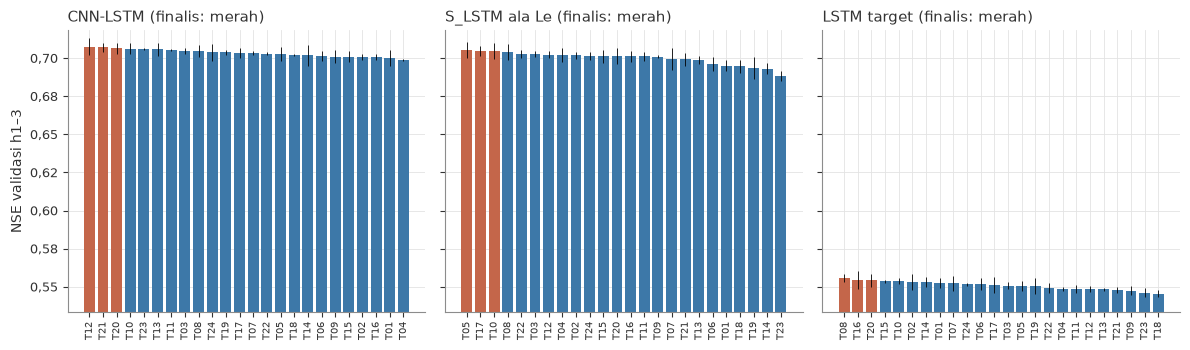

rata-rata NSE h1-3 titik desain menurut nilai faktor:
model                CNN-LSTM  S_LSTM ala Le  LSTM target
faktor       nilai                                       
dropout      0.1       0.7027         0.6969       0.5515
             0.25      0.7041         0.7011       0.5501
             0.4       0.7034         0.7015       0.5508
kernel       2         0.7035            NaN          NaN
             3         0.7033            NaN          NaN
lapisan_konv 1         0.7042            NaN          NaN
             2         0.7026            NaN          NaN
lapisan_lstm 1         0.7035         0.7004       0.5527
             2         0.7033         0.6993       0.5489
lr           0.0005    0.7033         0.6979       0.5500
             0.001     0.7034         0.7018       0.5516
unit         128       0.7041         0.6962       0.5503
             32        0.7032         0.7015       0.5516
             64        0.7029         0.7018       0.5504


In [26]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for a_, m_ in zip(ax, ["cnn_lstm", "s_lstm", "lstm_target"]):
    r_ = R_B[m_]
    x_ = np.arange(len(r_))
    warna = [WARNA["aksen"] if t in FINALIS[m_] else WARNA["utama"] for t in r_.index]
    a_.bar(x_, r_["NSE_h13"], yerr=r_["sb"], color=warna, error_kw=dict(lw=0.6))
    a_.set_xticks(x_); a_.set_xticklabels(r_.index, rotation=90, fontsize=7)
    a_.set_title(f"{NAMA_MODEL[m_]} (finalis: merah)", loc="left")
ax[0].set_ylabel("NSE validasi h1–3")
lo_ = min((R_B[m_]["NSE_h13"] - R_B[m_]["sb"]).min() for m_ in R_B)
hi_ = max((R_B[m_]["NSE_h13"] + R_B[m_]["sb"]).max() for m_ in R_B)
ax[0].set_ylim(lo_ - 0.01, hi_ + 0.005); sumbu_koma(ax[0], d=2)
fig.tight_layout()
simpan_gambar(fig, "tahap_B_lhs")

# rata-rata NSE h1-3 per nilai faktor (efek marginal di dalam desain)
baris = []
for m_ in R_B:
    for f in [c for c in FAKTOR_CNN if c in R_B[m_].columns]:
        for v, g in R_B[m_].groupby(f)["NSE_h13"]:
            baris.append({"model": NAMA_MODEL[m_], "faktor": f, "nilai": f"{v:g}", "NSE_h13": g.mean()})
marg = pd.DataFrame(baris).pivot_table(index=["faktor", "nilai"], columns="model", values="NSE_h13")
print("rata-rata NSE h1-3 titik desain menurut nilai faktor:")
print(marg[[NAMA_MODEL[m_] for m_ in R_B]].round(4).to_string())

### Hasil

- 630 run baru dilatih dengan 2 proses dalam 1,9 jam (rata-rata 22, 20, dan 18
  detik per run untuk CNN-LSTM, S_LSTM, dan LSTM target).
- **Hiperparameter hampir tidak berpengaruh pada NSE.** Ke-24 titik CNN-LSTM
  berada di antara 0,699 dan 0,708; titik terbaik (T12, 0,708 ± 0,006) hanya
  0,001 di atas pengaturan tengah (0,707). Selisih tiga titik teratas lebih kecil
  dari simpangan baku antar-seed-nya (0,003–0,006).
- Rata-rata per nilai faktor untuk CNN-LSTM berbeda paling banyak 0,002.
  S_LSTM lebih peka: 128 unit (0,696) dan dropout 0,1 (0,697) lebih rendah
  daripada 32–64 unit dan dropout 0,25–0,4 (0,701–0,702). LSTM target lebih baik
  dengan 1 lapisan (0,553 dibanding 0,549).
- Finalis: CNN-LSTM T12, T21, T20; S_LSTM T05, T17, T10; LSTM target T08, T16,
  T20.

## 13. Finalis: 8 seed dan kalibrasi MC Dropout

Dasar: [Kratzert2019] untuk 8 seed; [Klotz2022] untuk memilih hiperparameter MC
Dropout dari kalibrasi; [Gal2016] dan [Le2025] untuk MC Dropout 1.000 lintasan;
[Ghobadi2022] untuk PICP dan MPIW; interval kuantil 2,5–97,5% dari lintasan:
pilihan sendiri

Setiap finalis dilatih dengan 8 seed (0–7). Seed 0–2 sudah ada dari pencarian,
tetapi bobotnya tidak disimpan, sehingga ketiganya dilatih ulang; hasil latih
ulang harus identik dengan run tercatat (assert di `jalankan_finalis`). Bobot
setiap run finalis disimpan di `cache/bobot/`.

Untuk setiap run, MC Dropout dijalankan pada bagian validasi: dropout tetap aktif
di lapisan yang sama dengan saat latih, 1.000 lintasan per sampel. Dari lintasan
itu dihitung:

- PICP dan MPIW ±1σ (nominal 68,3%), dari rata-rata ± simpangan baku lintasan;
- PICP dan MPIW 95%, dari kuantil 2,5% dan 97,5% lintasan.

PICP dihitung per run, lalu dirata-rata atas horizon dan seed.

**Aturan pemilihan finalis**, ditulis sebelum hasil dilihat:

1. Finalis layak bila NSE h1–3 (8 seed) ≥ NSE finalis terbaik − simpangan baku
   antar-seed finalis terbaik.
2. Dari finalis yang layak, dipilih yang selisih PICP 95%-nya dari 0,95 paling
   kecil.
3. Kalau selisih kalibrasi dua finalis yang layak berbeda kurang dari simpangan
   baku antar-seed selisih kalibrasi finalis yang terkalibrasi terbaik, keduanya
   dianggap setara, dan dipilih model terkecil (jumlah parameter).

In [27]:
SEED_FINAL = list(range(8))
t0 = time.perf_counter()
latih_langkah("B_finalis", [dict(model=m_, cfg=DESAIN[m_].loc[t, "cfg"], **KONF_A) for m_ in FINALIS for t in FINALIS[m_]],
              seeds=SEED_FINAL, finalis=True)
print(f"waktu finalis: {(time.perf_counter() - t0) / 60:.1f} menit")

baris = []
for m_ in FINALIS:
    for t in FINALIS[m_]:
        tab = jalankan_pilihan("B_finalis", t, model=m_, cfg=DESAIN[m_].loc[t, "cfg"], seeds=SEED_FINAL,
                               finalis=True, cetak=False, **KONF_A)
        for r in tab.itertuples():
            baris.append({"model": m_, "titik": t, "horizon": r.horizon, "seed": r.seed, "id_run": r.id_run,
                          "n_param": r.n_param, "NSE": r.NSE, "KGE": r.KGE, **pm.ringkas_mc(r.id_run)})
FIN = pd.DataFrame(baris)
FIN["dev95"] = (FIN["PICP95"] - 0.95).abs()
FIN.round(5).to_csv(HASIL / "tahap_b_finalis_per_run.csv", index=False)
print(f"MC Dropout: rata-rata {FIN['detik_mc'].mean():.1f} detik per run (1.000 lintasan x {ribu(DATA_A[1]['y_val'].size)} sampel)")

per_seed = FIN.groupby(["model", "titik", "seed"])[["NSE", "PICP68", "PICP95", "MPIW68", "MPIW95", "dev95"]].mean()
RF = per_seed.groupby(["model", "titik"]).agg(["mean", "std"])
RF.columns = [f"{a}_{b}" for a, b in RF.columns]
RF["n_param"] = FIN.groupby(["model", "titik"])["n_param"].first()
PILIHAN_B = {}
for m_ in FINALIS:
    r_ = RF.loc[m_].loc[FINALIS[m_]]
    terbaik = r_["NSE_mean"].idxmax()
    batas = r_.loc[terbaik, "NSE_mean"] - r_.loc[terbaik, "NSE_std"]
    layak = list(r_.index[r_["NSE_mean"] >= batas])
    kal = r_.loc[layak, "dev95_mean"].idxmin()
    setara = [t for t in layak if r_.loc[t, "dev95_mean"] - r_.loc[kal, "dev95_mean"] < r_.loc[kal, "dev95_std"]]
    dipilih = min(setara, key=lambda t: r_.loc[t, "n_param"])
    PILIHAN_B[m_] = dipilih
    t_ = pd.DataFrame({
        "param": r_["n_param"].map(ribu),
        "NSE_h13 (8 seed)": [koma(a, d=3) + " ± " + koma(s, d=3) for a, s in zip(r_["NSE_mean"], r_["NSE_std"])],
        "PICP68": r_["PICP68_mean"].map(lambda x: koma(x, d=3)), "MPIW68": r_["MPIW68_mean"].map(lambda x: koma(x, d=1)),
        "PICP95": [koma(a, d=3) + " ± " + koma(s, d=3) for a, s in zip(r_["PICP95_mean"], r_["PICP95_std"])],
        "MPIW95": r_["MPIW95_mean"].map(lambda x: koma(x, d=1)),
        "|PICP95-0,95|": [koma(a, d=3) + " ± " + koma(s, d=3) for a, s in zip(r_["dev95_mean"], r_["dev95_std"])]})
    print(f"\n{NAMA_MODEL[m_]}: NSE terbaik {terbaik}, batas layak {koma(batas, d=4)}, layak: {', '.join(layak)}; "
          f"kalibrasi terbaik di antara yang layak: {kal}; setara: {', '.join(setara)}; dipilih: {dipilih}")
    print(t_.to_string())
RF.round(5).to_csv(HASIL / "tahap_b_finalis_ringkasan.csv")

B_finalis: 216 run, 216 dikerjakan dengan 2 proses dalam 43.0 menit, 0 sudah selesai sebelumnya
waktu finalis: 43.0 menit


MC Dropout: rata-rata 2.6 detik per run (1.000 lintasan x 1.370 sampel)

CNN-LSTM: NSE terbaik T21, batas layak 0,7044, layak: T12, T21; kalibrasi terbaik di antara yang layak: T21; setara: T21; dipilih: T21
           param NSE_h13 (8 seed) PICP68 MPIW68         PICP95 MPIW95  |PICP95-0,95|
titik                                                                               
T12       70.465    0,706 ± 0,004  0,507   55,7  0,732 ± 0,014  108,7  0,218 ± 0,014
T21    1.184.769    0,708 ± 0,003  0,523   64,8  0,762 ± 0,020  126,5  0,188 ± 0,020
T20       68.449    0,704 ± 0,004  0,608   83,7  0,819 ± 0,017  163,0  0,131 ± 0,017

S_LSTM ala Le: NSE terbaik T05, batas layak 0,6988, layak: T05, T17, T10; kalibrasi terbaik di antara yang layak: T05; setara: T05; dipilih: T05
        param NSE_h13 (8 seed) PICP68 MPIW68         PICP95 MPIW95  |PICP95-0,95|
titik                                                                            
T05    93.249    0,703 ± 0,004  0,588   77,3  0,808 ± 0,0

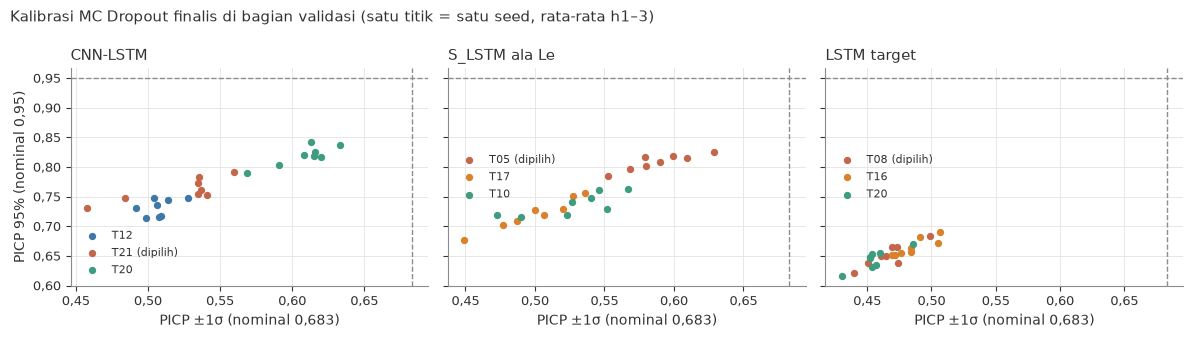

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a_, m_ in zip(ax, FINALIS):
    for j, t in enumerate(FINALIS[m_]):
        g = FIN[(FIN["model"] == m_) & (FIN["titik"] == t)]
        warna = WARNA["aksen"] if t == PILIHAN_B[m_] else list(PALET.values())[j]
        a_.scatter(g.groupby("seed")["PICP68"].mean(), g.groupby("seed")["PICP95"].mean(), s=18, color=warna,
                   label=f"{t}{' (dipilih)' if t == PILIHAN_B[m_] else ''}")
    a_.axvline(0.683, color=BATAS, lw=1, ls="--"); a_.axhline(0.95, color=BATAS, lw=1, ls="--")
    a_.set_xlabel("PICP ±1σ (nominal 0,683)"); a_.set_title(NAMA_MODEL[m_], loc="left"); a_.legend(fontsize=8)
    sumbu_koma(a_, "x", d=2)
ax[0].set_ylabel("PICP 95% (nominal 0,95)"); sumbu_koma(ax[0], d=2)
fig.suptitle("Kalibrasi MC Dropout finalis di bagian validasi (satu titik = satu seed, rata-rata h1–3)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
simpan_gambar(fig, "tahap_B_kalibrasi_finalis")

### Hasil

- 216 run finalis selesai dalam 43 menit. Ke-81 run seed 0–2 yang dilatih ulang
  untuk menyimpan bobot identik dengan run tercatat (assert lolos). MC Dropout
  1.000 lintasan memerlukan rata-rata 2,6 detik per run.
- **MC Dropout jauh di bawah nominal di semua finalis.** PICP 95% hanya
  0,64–0,82 (nominal 0,95) dan PICP ±1σ 0,46–0,61 (nominal 0,683). Ketidakpastian
  diremehkan, sesuai dengan temuan Klotz dkk. (2022) bahwa MC Dropout memberi
  estimasi ketidakpastian paling buruk. Dropout yang lebih tinggi memberi
  interval lebih lebar dan kalibrasi lebih baik: finalis dengan dropout 0,4
  paling dekat ke nominal (CNN-LSTM T20 0,819; S_LSTM T05 0,808).
- **CNN-LSTM: dipilih T21** (lr 0,001; 128 unit; 2 lapisan LSTM; dropout 0,25;
  kernel 3; 1 lapisan konvolusi; 1,18 juta parameter), dengan NSE 0,708 ± 0,003
  (8 seed) dan PICP 95% 0,762. T20 paling terkalibrasi (0,819) dan 17 kali lebih
  kecil, tetapi NSE-nya (0,70436) berada 0,00005 di bawah batas layak (0,70441).
  Aturan dipakai apa adanya, walaupun keputusan ini praktis berada tepat di
  batas. T12, yang 17 kali lebih kecil,
  layak, tetapi selisih kalibrasinya dari T21 (0,030) lebih besar dari
  simpangan baku antar-seed T21 (0,020), sehingga tidak setara.
- **S_LSTM: dipilih T05** (lr 0,001; 64 unit; 2 lapisan; dropout 0,4), dengan
  NSE 0,703 ± 0,004 dan PICP 95% 0,808. Ketiga finalis layak, dan T05 paling
  terkalibrasi dengan selisih yang jelas.
- **LSTM target: dipilih T08** (lr 0,001; 64 unit; 1 lapisan; dropout 0,1), dengan
  NSE 0,553 ± 0,006 dan PICP 95% 0,651. T16 paling terkalibrasi (0,665), tetapi
  selisihnya dari T08 lebih kecil dari simpangan baku antar-seed, jadi keduanya
  setara. Ukurannya sama (19.265 parameter, hanya learning rate yang berbeda),
  sehingga dipilih T08, yang NSE-nya lebih tinggi.

## 14. Ringkasan tahap B

Dasar: deskriptif

Konfigurasi terpilih setiap jaringan, dengan NSE validasi 8 seed dan kalibrasi
MC Dropout, dibandingkan dengan pengaturan tengah pada konfigurasi data yang
sama (tahap 10). Pilihan disimpan ke `modeling/hasil/pilihan_tahap_b.json`.
`konfigurasi_final.json` belum ditulis dan belum dikunci; berkas itu ditulis
setelah ablasi dan persetujuan.

In [29]:
ringkas_b = []
for m_ in FINALIS:
    t = PILIHAN_B[m_]
    r_ = RF.loc[(m_, t)]
    tengah = TAB_P.loc[NAMA_MODEL[m_]]
    ringkas_b.append({"model": NAMA_MODEL[m_], "titik": t,
                      **{k: DESAIN[m_].loc[t, k] for k in FAKTOR_CNN if k in DESAIN[m_].columns},
                      "param": int(r_["n_param"]), "NSE_h13_8seed": r_["NSE_mean"], "sb": r_["NSE_std"],
                      "PICP68": r_["PICP68_mean"], "PICP95": r_["PICP95_mean"], "MPIW95": r_["MPIW95_mean"],
                      "NSE_h13_tengah_3seed": tengah["NSE_h1-3"]})
RB = pd.DataFrame(ringkas_b).set_index("model")
per_h = FIN.groupby(["model", "titik", "horizon"])["NSE"].mean()
for h in HORIZON:
    RB[f"NSE_h{h}"] = [per_h.loc[(m_, PILIHAN_B[m_], h)] for m_ in FINALIS]
RB.round(5).to_csv(HASIL / "tahap_b_ringkasan.csv")
simpan_b = {"konfigurasi_data": KONF_A, "mesin": pm.mesin(), "desain": {"seed": 0, "kembar_awal_dan_penukaran": {"cnn_lstm": list(seed_cnn), "lstm": list(seed_lstm)}},
            "model": {m_: {"titik": PILIHAN_B[m_], "cfg": DESAIN[m_].loc[PILIHAN_B[m_], "cfg"],
                           "finalis": FINALIS[m_]} for m_ in FINALIS}}
(HASIL / "pilihan_tahap_b.json").write_text(json.dumps(simpan_b, indent=2, ensure_ascii=False))
print(json.dumps(simpan_b["model"], indent=1, ensure_ascii=False))
print()
print(RB.round(4).to_string())

{
 "cnn_lstm": {
  "titik": "T21",
  "cfg": {
   "lr": 0.001,
   "unit": 128,
   "lapisan_lstm": 2,
   "dropout": 0.25,
   "kernel": 3,
   "lapisan_konv": 1
  },
  "finalis": [
   "T12",
   "T21",
   "T20"
  ]
 },
 "s_lstm": {
  "titik": "T05",
  "cfg": {
   "lr": 0.001,
   "unit": 64,
   "lapisan_lstm": 2,
   "dropout": 0.4,
   "kernel": 2,
   "lapisan_konv": 1
  },
  "finalis": [
   "T05",
   "T17",
   "T10"
  ]
 },
 "lstm_target": {
  "titik": "T08",
  "cfg": {
   "lr": 0.001,
   "unit": 64,
   "lapisan_lstm": 1,
   "dropout": 0.1,
   "kernel": 2,
   "lapisan_konv": 1
  },
  "finalis": [
   "T08",
   "T16",
   "T20"
  ]
 }
}

              titik     lr  unit  lapisan_lstm  dropout  kernel  lapisan_konv    param  NSE_h13_8seed      sb  PICP68  PICP95    MPIW95  NSE_h13_tengah_3seed  NSE_h1  NSE_h2  NSE_h3
model                                                                                                                                                                                

### Hasil

| Model | Konfigurasi | Parameter | NSE h1–3 (8 seed) | NSE h1 / h2 / h3 | PICP 95% | NSE pengaturan tengah |
|---|---|---|---|---|---|---|
| CNN-LSTM | T21: lr 0,001; 128 unit; 2 LSTM; dropout 0,25; kernel 3; 1 konv | 1.184.769 | 0,708 ± 0,003 | 0,952 / 0,704 / 0,467 | 0,762 | 0,707 |
| S_LSTM ala Le | T05: lr 0,001; 64 unit; 2 LSTM; dropout 0,4 | 93.249 | 0,703 ± 0,004 | 0,954 / 0,701 / 0,455 | 0,808 | 0,703 |
| LSTM target | T08: lr 0,001; 64 unit; 1 LSTM; dropout 0,1 | 19.265 | 0,553 ± 0,006 | 0,800 / 0,504 / 0,354 | 0,651 | 0,549 |

- Tuning hampir tidak mengubah NSE dibanding pengaturan tengah (paling banyak
  +0,004). Faktor data dari tahap A, terutama sumber hujan, jauh lebih
  berpengaruh daripada hiperparameter.
- **Selisih CNN-LSTM dengan S_LSTM setelah tuning yang sama adalah 0,004**,
  sekitar satu simpangan baku antar-seed. CNN-LSTM lebih baik pada horizon 3
  (0,467 dan 0,455), S_LSTM sedikit lebih baik pada horizon 1 (0,954 dan
  0,952). Di bagian validasi, keunggulan konvolusi sumbu pos belum dapat
  dibedakan dari variasi antar-seed.
- Kalibrasi MC Dropout semua model terpilih jauh di bawah nominal (PICP 95%
  0,65–0,81). Ruang dropout yang diuji paling tinggi 0,4, sedangkan Klotz dkk.
  (2022) menguji sampai 0,75 dan memilih 0,75 berdasarkan kalibrasi.
- `konfigurasi_final.json` belum ditulis. Ablasi (urutan pos, atribut statis,
  skenario data Le2025) belum dijalankan.

---
# Bagian IV — Tahap R: hujan stasiun v2

## 15. Varian hujan R0–R5

Dasar: preprocessing Bagian VIII (tahap 31–36) untuk kanal hujan v2;
[Bardossy2008] untuk kerapatan jaringan; [Thornton2021] untuk jam pengamatan;
[Kratzert2019] untuk hujan rata-rata DAS; [Kratzert2021] untuk beberapa sumber
forcing; aturan setara dan pemilihan: tahap 2

Sensitivitas di tahap 9 menunjukkan bahwa hampir seluruh keunggulan GHCN atas
Daymet berasal dari tiga stasiun bandara. Preprocessing Bagian VIII menyiapkan
jaringan 43 stasiun, klasifikasi jam pengamatan, hujan per jam HPD, dan hujan
rata-rata wilayah DAS di `processed/v2/`. Varian yang diuji:

| Kode | Isi | Membandingkan |
|---|---|---|
| R0 | GHCN IDW 50 km di titik pos, 16 stasiun (konfigurasi tahap A) | acuan |
| R1 | P1: 43 stasiun, IDW di titik pos | dampak kerapatan |
| R2 | P1 + P3: 43 stasiun, rata-rata IDW grid 1 km per DAS | titik vs wilayah |
| R3 | P1 + P2: kanal bacaan pagi dan kanal hari yang sama, dengan cara pemetaan terpilih dari R1/R2 | dampak jam pengamatan |
| R4 | R3 + P2b: HPD per jam di kanal hari yang sama | dampak stasiun per jam |
| R5 | varian terpilih dari R1–R4 + kanal Daymet tergeser (P4) | sinergi sumber |

Semua varian memakai konfigurasi tahap A yang terkunci (V17, jendela 8 hari,
log1p) dan CNN-LSTM pengaturan tengah, 3 seed × 3 horizon, dengan aturan setara
tahap 2. Langkahnya berurutan:

1. R0, R1, R2. Cara pemetaan untuk R3 dan R4 dipilih dari R1 dan R2 dengan aturan
   setara; titik lebih sederhana daripada wilayah DAS.
2. R3 dan R4 dengan cara pemetaan itu.
3. Dasar R5 dipilih dari R1–R4 dengan aturan setara, lalu R5 = dasar + Daymet.
4. Varian akhir dipilih dari R0–R5. Urutan kesederhanaan R0, R1, R2, R3, R4, R5:
   lebih sedikit stasiun, pemetaan titik sebelum grid, lalu jumlah kanal.

Tahap B dilakukan dengan R0. Hasil tahap R dilaporkan dulu dan belum mengubah
pilihan tahap B.

Tampilkan dulu: jumlah kanal per pos, sampel, dan tanggal target validasi setiap
varian. R0 dari `processed/v2/` harus identik dengan tensor tahap A (hujan GHCN
IDW), sehingga run R0 diambil dari log tahap A tanpa dilatih ulang.

In [4]:
import hashlib
VAR_V2 = pm.varian_v2()
cek_r = []
for h in HORIZON:
    a_ = pm.muat_latih_val(h, "V17", 8, "ghcn_idw", "log1p")
    b_ = pm.muat_latih_val(h, "V17", 8, "v2_R0", "log1p")
    assert all(np.array_equal(a_[k], b_[k]) for k in ["X_latih", "y_latih", "idx_latih", "X_val", "y_val", "idx_val", "murni_val"])
    for kode in VAR_V2:
        d_ = pm.muat_latih_val(h, "V17", 8, f"v2_{kode}", "log1p")
        assert np.array_equal(d_["idx_val"], a_["idx_val"]) and np.array_equal(d_["idx_latih"], a_["idx_latih"])
        assert np.array_equal(d_["y_val"], a_["y_val"])
        if h == 1:
            cek_r.append({"varian": kode, "kanal_per_pos": d_["X_val"].shape[-1], "sampel_latih": len(d_["y_latih"]),
                          "sampel_validasi": len(d_["y_val"]), "tanggal_val": hashlib.md5(d_["idx_val"].tobytes()).hexdigest()[:10],
                          "kanal_hujan": ", ".join(VAR_V2[kode]["kanal_hujan"])})
print("R0 (processed/v2) identik dengan tensor tahap A V17, jendela 8, GHCN IDW, log1p pada h1-h3: True")
print("semua varian: sampel latih, sampel validasi, tanggal target, dan y sama pada h1-h3: True\n")
print(pd.DataFrame(cek_r).set_index("varian").to_string())
NAMA_LANGKAH["R"] = "hujan_v2"

def kode_r(label):
    # label varian R di tabel -> nilai kolom hujan pada log run
    return "ghcn_idw" if label == "R0" else f"v2_{label}"

def jalankan_r(daftar):
    latih_langkah("R", [dict(jendela=8, hujan=kode_r(k)) for k in daftar])
    return pd.concat([jalankan_pilihan("R", k, jendela=8, hujan=kode_r(k)) for k in daftar], ignore_index=True)

R0 (processed/v2) identik dengan tensor tahap A V17, jendela 8, GHCN IDW, log1p pada h1-h3: True
semua varian: sampel latih, sampel validasi, tanggal target, dan y sama pada h1-h3: True

             kanal_per_pos  sampel_latih  sampel_validasi tanggal_val                                  kanal_hujan
varian                                                                                                            
R0                      10          6384             1370  af94cf8959                             ghcn16_idw_titik
R1                      10          6384             1370  af94cf8959                              rapat_idw_titik
R2                      10          6384             1370  af94cf8959                                    rapat_das
R3_titik                11          6384             1370  af94cf8959                       pagi_titik, sama_titik
R3_das                  11          6384             1370  af94cf8959                           pagi_das, sama_das
R4_titik

In [5]:
t0 = time.perf_counter()
tab_r = jalankan_r(["R0", "R1", "R2"])
R_R12 = ringkas_pilihan(tab_r, ["R0", "R1", "R2"])
_, batas_m, setara_m, cara = pilih(R_R12.loc[["R1", "R2"]], ["R1", "R2"])
CARA = {"R1": "titik", "R2": "das"}[cara]
print(f"\n{tampil_ringkas(R_R12).rename_axis('varian').to_string()}")
print(f"\ncara pemetaan untuk R3/R4 (aturan setara antara R1 dan R2): batas {koma(batas_m, d=4)}, setara "
      f"{', '.join(setara_m)} -> {cara} ({CARA})")

R3, R4 = f"R3_{CARA}", f"R4_{CARA}"
tab_r = pd.concat([tab_r, jalankan_r([R3, R4])], ignore_index=True)
R_R14 = ringkas_pilihan(tab_r, ["R0", "R1", "R2", R3, R4])
_, batas_d, setara_d, dasar5 = pilih(R_R14.loc[["R1", "R2", R3, R4]], ["R1", "R2", R3, R4])
R5 = f"R5_{dasar5}"
print(f"\ndasar R5 (aturan setara di antara R1-R4): batas {koma(batas_d, d=4)}, setara {', '.join(setara_d)} -> {dasar5}")
tab_r = pd.concat([tab_r, jalankan_r([R5])], ignore_index=True)
URUTAN_R = ["R0", "R1", "R2", R3, R4, R5]
R_R = ringkas_pilihan(tab_r, URUTAN_R)
terbaik_r, batas_r, setara_r, terpilih_r = pilih(R_R, URUTAN_R)
R_R["kanal_per_pos"] = [VAR_V2[k]["kanal_per_pos"] if k != "R0" else 10 for k in URUTAN_R]
R_R["n_param"] = tab_r.groupby("pilihan")["n_param"].first().loc[URUTAN_R]
print(f"\nwaktu: {(time.perf_counter() - t0) / 60:.1f} menit\n")
print(tampil_ringkas(R_R.drop(columns=["kanal_per_pos", "n_param"])).join(R_R[["kanal_per_pos", "n_param"]])
      .rename_axis("varian").to_string())
print(f"\nterbaik: {terbaik_r}; batas setara: {koma(batas_r, d=4)}; setara: {', '.join(setara_r)}; terpilih: {terpilih_r}")
ref_r = R_R.loc["R0"]
print(f"\nselisih terhadap R0 (sb antar-seed R0 = {koma(ref_r['sb'], d=4)}):")
for k in URUTAN_R[1:]:
    d_ = R_R.loc[k, "NSE_h13"] - ref_r["NSE_h13"]
    print(f"  {k:>12}: {d_:+.4f} ({d_ / ref_r['sb']:+.1f} sb); h1 {R_R.loc[k, 'NSE_h1'] - ref_r['NSE_h1']:+.4f}, "
          f"h2 {R_R.loc[k, 'NSE_h2'] - ref_r['NSE_h2']:+.4f}, h3 {R_R.loc[k, 'NSE_h3'] - ref_r['NSE_h3']:+.4f}")

R: 27 run, 18 dikerjakan dengan 2 proses dalam 3.3 menit, 9 sudah selesai sebelumnya
                      R0: NSE h1-3 0,950, 0,707, 0,465; rata-rata 89 epoch, 20 detik per run


                      R1: NSE h1-3 0,947, 0,697, 0,458; rata-rata 80 epoch, 20 detik per run


                      R2: NSE h1-3 0,942, 0,689, 0,448; rata-rata 85 epoch, 21 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

       NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
varian                                                       
R0      0,950  0,707  0,465  0,707 ± 0,001   0,745         89
R1      0,947  0,697  0,458  0,701 ± 0,002   0,738         80
R2      0,942  0,689  0,448  0,693 ± 0,001   0,734         85

cara pemetaan untuk R3/R4 (aturan setara antara R1 dan R2): batas 0,6989, setara R1 -> R1 (titik)


R: 18 run, 18 dikerjakan dengan 2 proses dalam 3.0 menit, 0 sudah selesai sebelumnya


                R3_titik: NSE h1-3 0,955, 0,707, 0,475; rata-rata 75 epoch, 19 detik per run


                R4_titik: NSE h1-3 0,953, 0,705, 0,470; rata-rata 73 epoch, 18 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

dasar R5 (aturan setara di antara R1-R4): batas 0,7092, setara R3_titik -> R3_titik


R: 9 run, 9 dikerjakan dengan 2 proses dalam 1.9 menit, 0 sudah selesai sebelumnya


             R5_R3_titik: NSE h1-3 0,953, 0,710, 0,468; rata-rata 85 epoch, 21 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

waktu: 8.2 menit

            NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata  kanal_per_pos  n_param
varian                                                                                    
R0           0,950  0,707  0,465  0,707 ± 0,001   0,745         89             10   313217
R1           0,947  0,697  0,458  0,701 ± 0,002   0,738         80             10   313217
R2           0,942  0,689  0,448  0,693 ± 0,001   0,734         85             10   313217
R3_titik     0,955  0,707  0,475  0,712 ± 0,003   0,759         75             11   313345
R4_titik     0,953  0,705  0,470  0,709 ± 0,002   0,745         73             11   313345
R5_R3_titik  0,953  0,710  0,468  0,711 ± 0,002   0,752         85             12   313473

terbaik: R3_titik; batas setara: 0,7092; setara: R3_titik, R5_

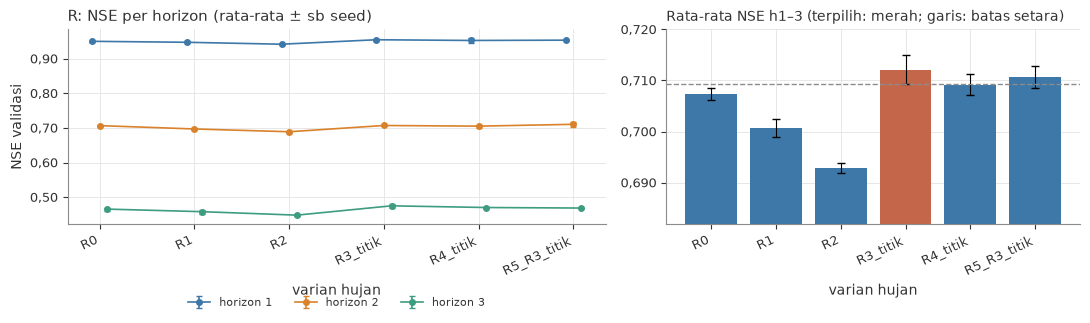

{
  "cara_pemetaan_R3_R4": "titik",
  "dasar_R5": "R3_titik",
  "urutan": [
    "R0",
    "R1",
    "R2",
    "R3_titik",
    "R4_titik",
    "R5_R3_titik"
  ],
  "terbaik": "R3_titik",
  "batas_setara": 0.70922,
  "setara": [
    "R3_titik",
    "R5_R3_titik"
  ],
  "terpilih": "R3_titik",
  "hujan_log": "v2_R3_titik",
  "kanal_per_pos": 11,
  "kanal_hujan": [
    "pagi_titik",
    "sama_titik"
  ],
  "mesin": "x86_64-NVIDIA GeForce RTX 4060",
  "konfigurasi": {
    "varian": "V17",
    "jendela": 8,
    "transformasi": "log1p",
    "model": "cnn_lstm",
    "cfg": "pengaturan tengah",
    "seed": [
      0,
      1,
      2
    ]
  }
}


In [6]:
gambar_pilihan("R", R_R.drop(columns=["kanal_per_pos", "n_param"]), tab_r, terpilih_r, "varian hujan", rotasi=25)
tab_r.to_csv(HASIL / "tahap_r_per_run.csv", index=False)
R_R.round(5).to_csv(HASIL / "tahap_r_ringkasan.csv")
pilihan_r = {"cara_pemetaan_R3_R4": CARA, "dasar_R5": dasar5, "urutan": URUTAN_R, "terbaik": terbaik_r,
             "batas_setara": round(float(batas_r), 5), "setara": setara_r, "terpilih": terpilih_r,
             "hujan_log": kode_r(terpilih_r), "kanal_per_pos": int(R_R.loc[terpilih_r, "kanal_per_pos"]),
             "kanal_hujan": VAR_V2[terpilih_r]["kanal_hujan"] if terpilih_r != "R0" else ["ghcn16_idw_titik"],
             "mesin": pm.mesin(), "konfigurasi": {"varian": "V17", "jendela": 8, "transformasi": "log1p", "model": "cnn_lstm",
                                                  "cfg": "pengaturan tengah", "seed": SEED_SELEKSI}}
(HASIL / "pilihan_tahap_r.json").write_text(json.dumps(pilihan_r, indent=2, ensure_ascii=False))
print(json.dumps(pilihan_r, indent=2, ensure_ascii=False))

### Hasil

| Varian | Kanal per pos | NSE h1 / h2 / h3 | NSE h1–3 | Selisih dengan R0 |
|---|---|---|---|---|
| R0: 16 stasiun, titik | 10 | 0,950 / 0,707 / 0,465 | 0,707 ± 0,001 | — |
| R1: 43 stasiun, titik | 10 | 0,947 / 0,697 / 0,458 | 0,701 ± 0,002 | −0,007 |
| R2: 43 stasiun, wilayah DAS | 10 | 0,942 / 0,689 / 0,448 | 0,693 ± 0,001 | −0,015 |
| R3_titik: bacaan pagi + hari yang sama | 11 | 0,955 / 0,707 / 0,475 | **0,712 ± 0,003** | +0,005 |
| R4_titik: R3 + HPD | 11 | 0,953 / 0,705 / 0,470 | 0,709 ± 0,002 | +0,002 |
| R5_R3_titik: R3 + Daymet | 12 | 0,953 / 0,710 / 0,468 | 0,711 ± 0,002 | +0,003 |

- **Perapatan saja menurunkan NSE.** R1 0,006 di bawah R0 (5,5 simpangan baku
  antar-seed R0), di ketiga horizon. Dengan 43 stasiun, 35 di antaranya bacaan pagi,
  kanal IDW tunggal makin didominasi bacaan pagi, sehingga hujan sore dan malam hari
  t dari bandara makin tertutup. Hasil ini sejalan dengan tahap 9: nilai GHCN
  terutama datang dari stasiun hari yang sama.
- **Rata-rata wilayah DAS lebih buruk daripada titik pos** (R2 0,693). Aturan setara
  memilih cara titik untuk R3 dan R4. Rata-rata grid mencampur jam pengamatan di
  seluruh DAS dan meratakan hujan lokal (hari hujan naik dari 33% ke 37% di pos
  target, preprocessing tahap 35). Wilayah DAS belum diuji dengan dua kanal terpisah,
  karena desain berurutan mengunci cara titik sebelum R3.
- **Memisahkan jam pengamatan memberi hasil terbaik.** R3_titik 0,712 ± 0,003, naik
  0,005 dari R0 (4 sb R0) dan 0,011 dari R1 dengan stasiun yang sama. Kenaikan
  terbesar di horizon 1 (+0,005) dan 3 (+0,010); horizon 2 sama.
- **HPD tidak menambah** (R4 0,709, di bawah batas setara 0,7092). Kelengkapan HPD
  2000–2024 hanya 53–88%, dan Mill Gap kosong total 2016–2018.
- **Daymet tidak memberi sinergi yang terukur.** R5 (0,711 ± 0,002) setara dengan R3,
  tetapi tidak lebih tinggi; menurut aturan tahap 2 dipilih yang lebih sederhana.
- **Terpilih: R3_titik**, 11 kanal per pos (debit, flag, hujan bacaan pagi IDW titik
  50 km, hujan hari yang sama 3 stasiun terdekat, Tmax, Tmin, 5 atribut). Jumlah
  parameter CNN-LSTM pengaturan tengah naik dari 313.217 menjadi 313.345 karena
  lapisan konvolusi menerima satu kanal tambahan.
- Selisih R3 dengan R0 (0,005) kecil dibanding selisih GHCN dengan Daymet di A2
  (0,036), dan diukur dengan 3 seed pada pengaturan tengah. Tahap B dijalankan
  dengan R0; pilihan R3 belum dipakai di tahap B dan ablasi.


**Keputusan.** Konfigurasi data dikunci ke **R3_titik**: V17, jendela 8 hari,
log1p, kanal hujan bacaan pagi (IDW titik 50 km) dan hari yang sama (3 stasiun
terdekat), 11 kanal per pos. Tahap B tidak diulang penuh. Hiperparameter tetap
hasil tahap B (CNN-LSTM T21, S_LSTM T05, LSTM target T08); hanya ketiga model
terpilih itu yang dilatih ulang dengan data R3_titik (tahap 17).

## 16. R3 dengan rata-rata wilayah DAS

Dasar: preprocessing tahap 35 (kanal `pagi_das` dan `sama_das`); laporan saja,
tidak mengubah pilihan

Desain berurutan di tahap 15 mengunci cara titik sebelum R3, sehingga dua kanal
jam pengamatan belum pernah diuji dengan rata-rata wilayah DAS. R3_das memakai
kedua kanal itu per DAS, dengan model dan seed yang sama.

In [7]:
NAMA_MODEL = {"lstm_target": "LSTM target", "s_lstm": "S_LSTM ala Le", "cnn_lstm": "CNN-LSTM"}
tab_w = pd.concat([tab_r, jalankan_r(["R3_das"])], ignore_index=True)
URUTAN_W = ["R0", "R1", "R2", "R3_titik", "R3_das"]
R_W = ringkas_pilihan(tab_w[tab_w["pilihan"].isin(URUTAN_W)], URUTAN_W)
print()
print(tampil_ringkas(R_W).rename_axis("varian").to_string())
d_w = R_W.loc["R3_das", "NSE_h13"] - R_W.loc["R3_titik", "NSE_h13"]
print(f"\nR3_das - R3_titik: {d_w:+.4f} ({d_w / R_W.loc['R3_titik', 'sb']:+.1f} sb antar-seed R3_titik); "
      f"R3_das - R2: {R_W.loc['R3_das', 'NSE_h13'] - R_W.loc['R2', 'NSE_h13']:+.4f}")
R_W.round(5).to_csv(HASIL / "tahap_r_wilayah_ringkasan.csv")

R: 9 run, 9 dikerjakan dengan 2 proses dalam 1.7 menit, 0 sudah selesai sebelumnya


                  R3_das: NSE h1-3 0,953, 0,709, 0,473; rata-rata 78 epoch, 19 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

         NSE_h1 NSE_h2 NSE_h3        NSE_h13 KGE_h13 epoch_rata
varian                                                         
R0        0,950  0,707  0,465  0,707 ± 0,001   0,745         89
R1        0,947  0,697  0,458  0,701 ± 0,002   0,738         80
R2        0,942  0,689  0,448  0,693 ± 0,001   0,734         85
R3_titik  0,955  0,707  0,475  0,712 ± 0,003   0,759         75
R3_das    0,953  0,709  0,473  0,712 ± 0,002   0,756         78

R3_das - R3_titik: -0.0005 (-0.2 sb antar-seed R3_titik); R3_das - R2: +0.0188


### Hasil

- **R3_das setara dengan R3_titik**: 0,712 ± 0,002 dibanding 0,712 ± 0,003 (selisih
  −0,0005, 0,2 simpangan baku antar-seed). Per horizon: 0,953 / 0,709 / 0,473
  dibanding 0,955 / 0,707 / 0,475.
- Dengan dua kanal jam pengamatan, rata-rata wilayah DAS tidak lagi kalah dari titik
  pos. R3_das naik 0,019 dari R2 (satu kanal, wilayah DAS), sedangkan R3_titik naik
  0,011 dari R1. Kelemahan R2 di tahap 15 terutama berasal dari pencampuran jam
  pengamatan, bukan dari rata-rata wilayahnya.
- Pilihan tetap R3_titik: kedua cara setara, dan titik lebih sederhana.

## 17. Model terpilih tahap B dengan data R3_titik

Dasar: tahap 13 (8 seed, MC Dropout 1.000 lintasan, PICP dan MPIW); regresi linear
dengan cara tahap 10; [Kratzert2019], [Gal2016], [Le2025], [Ghobadi2022]

Ketiga model terpilih tahap B dilatih ulang dengan data R3_titik, 8 seed (0–7) ×
3 horizon, dengan konfigurasi dari `modeling/hasil/pilihan_tahap_b.json`. Untuk
setiap run, MC Dropout 1.000 lintasan dihitung di bagian validasi, seperti tahap
13. Regresi linear dihitung ulang dengan kuadrat terkecil pada semua kanal hari
terakhir jendela (17 pos × 11 kanal + intersep). Klimatologi, persistensi, dan
ARIMA hanya memakai debit pos target, sehingga tidak diulang. Sebagai pembanding,
hasil model yang sama dengan data R0 diambil dari `tahap_b_finalis_per_run.csv`.

In [8]:
KONF_R = dict(varian="V17", jendela=8, hujan="v2_R3_titik", transformasi="log1p")
B_JSON = json.loads((HASIL / "pilihan_tahap_b.json").read_text())
assert B_JSON["konfigurasi_data"] == {"varian": "V17", "jendela": 8, "hujan": "ghcn_idw", "transformasi": "log1p"}
TERPILIH_B = {m_: (B_JSON["model"][m_]["titik"], B_JSON["model"][m_]["cfg"]) for m_ in ["cnn_lstm", "s_lstm", "lstm_target"]}
SEED_FINAL = list(range(8))
NAMA_LANGKAH["B_final_R3"] = "final_R3"
t0 = time.perf_counter()
latih_langkah("B_final_R3", [dict(model=m_, cfg=c, **KONF_R) for m_, (t, c) in TERPILIH_B.items()],
              seeds=SEED_FINAL, finalis=True)
print(f"waktu: {(time.perf_counter() - t0) / 60:.1f} menit")

baris = []
for m_, (t, c) in TERPILIH_B.items():
    tab = jalankan_pilihan("B_final_R3", t, model=m_, cfg=c, seeds=SEED_FINAL, finalis=True, cetak=False, **KONF_R)
    for r in tab.itertuples():
        baris.append({"model": m_, "titik": t, "horizon": r.horizon, "seed": r.seed, "id_run": r.id_run,
                      "n_param": r.n_param, "NSE": r.NSE, "KGE": r.KGE, **pm.ringkas_mc(r.id_run)})
FIN_R3 = pd.DataFrame(baris)
FIN_R3.round(5).to_csv(HASIL / "tahap_r3_final_per_run.csv", index=False)
FIN_R0 = pd.read_csv(HASIL / "tahap_b_finalis_per_run.csv")
FIN_R0 = pd.concat([FIN_R0[(FIN_R0["model"] == m_) & (FIN_R0["titik"] == t)] for m_, (t, _) in TERPILIH_B.items()])
assert len(FIN_R0) == len(FIN_R3) == 3 * 8 * 3

def ringkas_final(F):
    per_seed = F.groupby(["model", "seed"])[["NSE", "PICP68", "PICP95", "MPIW95"]].mean()
    g = per_seed.groupby("model")
    out = pd.DataFrame({"param": F.groupby("model")["n_param"].first()})
    for h in HORIZON:
        s_ = F[F["horizon"] == h].groupby("model")["NSE"]
        out[f"NSE_h{h}"], out[f"sb_h{h}"] = s_.mean(), s_.std()
    out["NSE_h13"], out["sb_h13"] = g["NSE"].mean(), g["NSE"].std()
    out["PICP95"], out["sb_PICP95"] = g["PICP95"].mean(), g["PICP95"].std()
    out["PICP68"], out["sb_PICP68"] = g["PICP68"].mean(), g["PICP68"].std()
    out["MPIW95"] = g["MPIW95"].mean()
    return out.loc[list(TERPILIH_B)]

RR3, RR0 = ringkas_final(FIN_R3), ringkas_final(FIN_R0)
# regresi linear (tahap 10) pada data R3_titik dan R0
reg = []
for nama_, konf_ in [("R3_titik", KONF_R), ("R0", dict(KONF_R, hujan="ghcn_idw"))]:
    for h in HORIZON:
        D = data_pilihan(h, **konf_)
        F_l = D["X_latih"][:, -1].reshape(len(D["X_latih"]), -1)
        F_v = D["X_val"][:, -1].reshape(len(D["X_val"]), -1)
        koef, *_ = np.linalg.lstsq(np.c_[np.ones(len(F_l)), F_l], D["y_latih"].astype(float), rcond=None)
        reg.append({"data": nama_, "horizon": h, "fitur": F_l.shape[1] + 1,
                    **metrik(ke_m3s(D["y_val"], D), ke_m3s(np.c_[np.ones(len(F_v)), F_v] @ koef, D))})
REG = pd.DataFrame(reg)
lama_reg = pd.read_csv(HASIL / "baseline_validasi_tahap_a_per_run.csv")
lama_reg = lama_reg[lama_reg["model"] == "regresi linear"].sort_values("horizon")
assert np.allclose(REG[REG["data"] == "R0"]["NSE"].to_numpy(), lama_reg["NSE"].to_numpy(), atol=1e-5), \
    "regresi linear R0 berbeda dengan tahap 10"
REG.round(5).to_csv(HASIL / "tahap_r3_regresi_linear.csv", index=False)

def sel_(a, s, d=3):
    return koma(a, d=d) + (" ± " + koma(s, d=3) if pd.notna(s) else "")

baris_t = []
for m_ in TERPILIH_B:
    for nama_, R_ in [("R3_titik", RR3), ("R0", RR0)]:
        r_ = R_.loc[m_]
        baris_t.append({"model": f"{NAMA_MODEL[m_]} {TERPILIH_B[m_][0]}", "data": nama_, "param": ribu(r_["param"]),
                        **{f"NSE h{h}": sel_(r_[f"NSE_h{h}"], r_[f"sb_h{h}"]) for h in HORIZON},
                        "NSE h1–3": sel_(r_["NSE_h13"], r_["sb_h13"]), "PICP 95%": sel_(r_["PICP95"], r_["sb_PICP95"]),
                        "PICP ±1σ": sel_(r_["PICP68"], r_["sb_PICP68"]), "MPIW 95% (m³/s)": koma(r_["MPIW95"], d=1)})
for nama_ in ["R3_titik", "R0"]:
    g_ = REG[REG["data"] == nama_].set_index("horizon")["NSE"]
    baris_t.append({"model": "regresi linear", "data": nama_, "param": ribu(REG[REG["data"] == nama_]["fitur"].iloc[0]),
                    **{f"NSE h{h}": koma(g_[h], d=3) for h in HORIZON}, "NSE h1–3": koma(g_.mean(), d=3),
                    "PICP 95%": "—", "PICP ±1σ": "—", "MPIW 95% (m³/s)": "—"})
TAB_F = pd.DataFrame(baris_t).set_index(["model", "data"])
print(f"MC Dropout: rata-rata {FIN_R3['detik_mc'].mean():.1f} detik per run; NSE per horizon: rata-rata ± sb atas 8 seed; "
      f"NSE h1–3 dan PICP: rata-rata ± sb antar-seed dari rata-rata h1–3\n")
print(TAB_F.to_string())
print("\nselisih R3_titik - R0 (NSE h1-3, dalam sb antar-seed R0):")
for m_ in TERPILIH_B:
    d_ = RR3.loc[m_, "NSE_h13"] - RR0.loc[m_, "NSE_h13"]
    print(f"  {NAMA_MODEL[m_]:14}: {d_:+.4f} ({d_ / RR0.loc[m_, 'sb_h13']:+.1f} sb); "
          f"PICP95 {RR3.loc[m_, 'PICP95'] - RR0.loc[m_, 'PICP95']:+.3f}")
d_ = REG.groupby("data")["NSE"].mean()
print(f"  {'regresi linear':14}: {d_['R3_titik'] - d_['R0']:+.4f}")
pd.concat({"R3_titik": RR3, "R0": RR0}, names=["data"]).round(5).to_csv(HASIL / "tahap_r3_final_ringkasan.csv")

B_final_R3: 72 run, 72 dikerjakan dengan 2 proses dalam 15.3 menit, 0 sudah selesai sebelumnya
waktu: 15.3 menit


MC Dropout: rata-rata 5.5 detik per run; NSE per horizon: rata-rata ± sb atas 8 seed; NSE h1–3 dan PICP: rata-rata ± sb antar-seed dari rata-rata h1–3

                                param         NSE h1         NSE h2         NSE h3       NSE h1–3       PICP 95%       PICP ±1σ MPIW 95% (m³/s)
model             data                                                                                                                         
CNN-LSTM T21      R3_titik  1.185.153  0,951 ± 0,004  0,709 ± 0,004  0,478 ± 0,006  0,713 ± 0,003  0,767 ± 0,024  0,520 ± 0,049           125,3
                  R0        1.184.769  0,952 ± 0,003  0,704 ± 0,004  0,467 ± 0,007  0,708 ± 0,003  0,762 ± 0,020  0,523 ± 0,034           126,5
S_LSTM ala Le T05 R3_titik     97.601  0,954 ± 0,002  0,706 ± 0,006  0,464 ± 0,011  0,708 ± 0,005  0,826 ± 0,025  0,613 ± 0,042           155,3
                  R0           93.249  0,954 ± 0,003  0,701 ± 0,004  0,455 ± 0,008  0,703 ± 0,004  0,808 ± 0,013  0,588 ± 0,024 

### Hasil

| Model | Data | NSE h1 | NSE h2 | NSE h3 | NSE h1–3 | PICP 95% | PICP ±1σ |
|---|---|---|---|---|---|---|---|
| CNN-LSTM T21 | R3_titik | 0,951 ± 0,004 | 0,709 ± 0,004 | 0,478 ± 0,006 | **0,713 ± 0,003** | 0,767 ± 0,024 | 0,520 ± 0,049 |
| | R0 | 0,952 ± 0,003 | 0,704 ± 0,004 | 0,467 ± 0,007 | 0,708 ± 0,003 | 0,762 ± 0,020 | 0,523 ± 0,034 |
| S_LSTM T05 | R3_titik | 0,954 ± 0,002 | 0,706 ± 0,006 | 0,464 ± 0,011 | 0,708 ± 0,005 | 0,826 ± 0,025 | 0,613 ± 0,042 |
| | R0 | 0,954 ± 0,003 | 0,701 ± 0,004 | 0,455 ± 0,008 | 0,703 ± 0,004 | 0,808 ± 0,013 | 0,588 ± 0,024 |
| LSTM target T08 | R3_titik | 0,835 ± 0,005 | 0,553 ± 0,008 | 0,372 ± 0,007 | 0,587 ± 0,006 | 0,705 ± 0,014 | 0,513 ± 0,014 |
| | R0 | 0,800 ± 0,004 | 0,504 ± 0,010 | 0,354 ± 0,005 | 0,553 ± 0,006 | 0,651 ± 0,020 | 0,466 ± 0,017 |
| Regresi linear | R3_titik | 0,911 | 0,626 | 0,378 | 0,638 | — | — |
| | R0 | 0,909 | 0,621 | 0,368 | 0,633 | — | — |

Nominal PICP 95% = 0,95 dan PICP ±1σ = 0,683; 8 seed, rata-rata ± simpangan baku.

- **Data R3_titik menaikkan NSE semua model.** CNN-LSTM +0,005 (1,7 sb), S_LSTM
  +0,005 (1,1 sb), regresi linear +0,006, dan LSTM target +0,034 (6 sb). Kenaikan
  CNN-LSTM dan S_LSTM ada di horizon 2 dan 3; horizon 1 tetap.
- LSTM target, yang hanya melihat kanal pos target, paling diuntungkan. Kanal hari
  yang sama memberinya hujan sore dan malam hari t di DAS pos target, yang tidak ada
  di kanal IDW tunggal yang didominasi Crozier.
- **Urutan model tidak berubah**: CNN-LSTM 0,713, S_LSTM 0,708, regresi linear 0,638,
  LSTM target 0,587. Selisih CNN-LSTM dengan S_LSTM 0,005, sekitar 1 sb antar-seed
  S_LSTM.
- **Kalibrasi MC Dropout tetap jauh di bawah nominal.** PICP 95% hanya 0,77 (CNN-LSTM),
  0,83 (S_LSTM), dan 0,71 (LSTM target); PICP ±1σ 0,51–0,61. Data R3_titik tidak
  mengubah kalibrasi CNN-LSTM (+0,005) dan sedikit memperbaiki S_LSTM dan LSTM
  target. MC Dropout rata-rata 5,5 detik per run.

## 18. Ablasi kontribusi data

Dasar: ablasi masukan bertahap, pilihan sendiri; konfigurasi CNN-LSTM T21 dari
tahap 13; aturan 3 seed × 3 horizon tahap 2

CNN-LSTM T21 dilatih dengan data R3_titik yang kanalnya ditambah bertahap:

| Langkah | Kanal per pos | Isi |
|---|---|---|
| (a) debit | 2 | debit dan flag isian (flag hanya penanda nilai debit isian, nol di pos target) |
| (b) + hujan | 4 | (a) + hujan bacaan pagi + hujan hari yang sama |
| (c) + suhu | 6 | (b) + Tmax + Tmin |
| (d) + atribut statis | 11 | lengkap, sama dengan R3_titik |

Sampel dan tanggal target sama untuk keempat langkah. Langkah (d) memakai run
seed 0–2 dari tahap 17.

a: debit                : debit_terskala, flag_isian


b: + hujan              : debit_terskala, flag_isian, pagi_titik, sama_titik


c: + suhu               : debit_terskala, flag_isian, pagi_titik, sama_titik, tmax_terskala, tmin_terskala
d: + atribut (lengkap)  : debit_terskala, flag_isian, pagi_titik, sama_titik, tmax_terskala, tmin_terskala, log_luas, elev_rata_das_m, kemiringan_das_m_per_km, hujan_tahunan_mm, bfi_latih


ablasi_data: 36 run, 27 dikerjakan dengan 2 proses dalam 5.3 menit, 9 sudah selesai sebelumnya


                a: debit: NSE h1-3 0,900, 0,615, 0,397; rata-rata 62 epoch, 19 detik per run


              b: + hujan: NSE h1-3 0,930, 0,671, 0,445; rata-rata 79 epoch, 23 detik per run


               c: + suhu: NSE h1-3 0,933, 0,679, 0,454; rata-rata 76 epoch, 22 detik per run
  d: + atribut (lengkap): NSE h1-3 0,953, 0,711, 0,477; rata-rata 80 epoch, 24 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

                               NSE h1         NSE h2         NSE h3       NSE h1–3  kanal per pos      param selisih h1–3
langkah                                                                                                                  
a: debit                0,900 ± 0,004  0,615 ± 0,003  0,397 ± 0,009  0,637 ± 0,005              2  1.181.697            —
b: + hujan              0,930 ± 0,004  0,671 ± 0,007  0,445 ± 0,008  0,682 ± 0,002              4  1.182.465       +0,045
c: + suhu               0,933 ± 0,006  0,679 ± 0,008  0,454 ± 0,006  0,689 ± 0,006              6  1.183.233       +0,007
d: + atribut (lengkap)  0,953 ± 0,003  0,711 ± 0,003  0,477 ± 0,005  0,714 ± 0,002             11  1.185.1

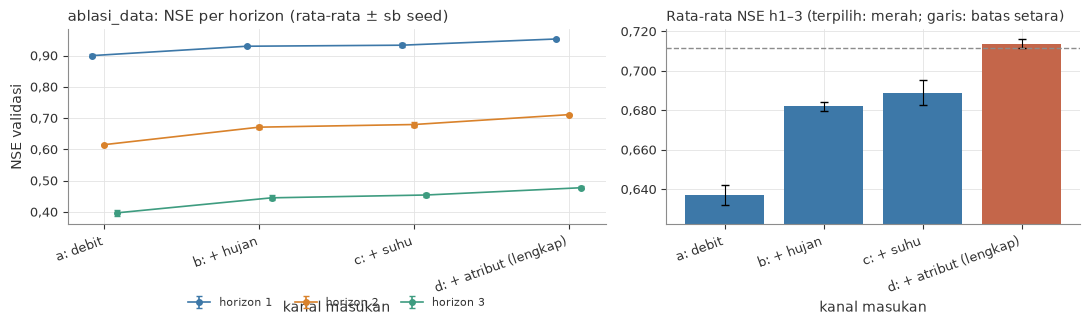

In [9]:
ABL = {"a: debit": "v2_R3_titik@debit", "b: + hujan": "v2_R3_titik@debit_hujan",
       "c: + suhu": "v2_R3_titik@debit_hujan_suhu", "d: + atribut (lengkap)": "v2_R3_titik"}
cfg_t21 = TERPILIH_B["cnn_lstm"][1]
NAMA_LANGKAH["ablasi_data"] = "kontribusi_data"
for lab, k in ABL.items():
    print(f"{lab:24}: {', '.join(data_pilihan(1, 'V17', 8, k)['kanal'])}")
latih_langkah("ablasi_data", [dict(model="cnn_lstm", cfg=cfg_t21, jendela=8, hujan=k) for k in ABL.values()])
tab_a = pd.concat([jalankan_pilihan("ablasi_data", lab, model="cnn_lstm", cfg=cfg_t21, jendela=8, hujan=k)
                   for lab, k in ABL.items()], ignore_index=True)
URUTAN_ABL = list(ABL)
R_ABL = ringkas_pilihan(tab_a, URUTAN_ABL)
sb_h = tab_a.pivot_table(index="pilihan", columns="horizon", values="NSE", aggfunc="std").loc[URUTAN_ABL]
TAB_ABL = pd.DataFrame({f"NSE h{h}": [sel_(R_ABL.loc[p, f"NSE_h{h}"], sb_h.loc[p, h]) for p in URUTAN_ABL] for h in HORIZON},
                       index=pd.Index(URUTAN_ABL, name="langkah"))
TAB_ABL["NSE h1–3"] = [sel_(a, s) for a, s in zip(R_ABL["NSE_h13"], R_ABL["sb"])]
TAB_ABL["kanal per pos"] = [data_pilihan(1, "V17", 8, k)["X_val"].shape[-1] for k in ABL.values()]
TAB_ABL["param"] = [ribu(v) for v in tab_a.groupby("pilihan")["n_param"].first().loc[URUTAN_ABL]]
TAB_ABL["selisih h1–3"] = ["—"] + [f"{d:+.3f}".replace(".", ",") for d in R_ABL["NSE_h13"].diff().iloc[1:]]
print()
print(TAB_ABL.to_string())
tab_a.to_csv(HASIL / "ablasi_data_per_run.csv", index=False)
R_ABL.round(5).to_csv(HASIL / "ablasi_data_ringkasan.csv")
gambar_pilihan("ablasi_data", R_ABL, tab_a, "d: + atribut (lengkap)", "kanal masukan", rotasi=20)

### Hasil

| Langkah | Kanal per pos | NSE h1 | NSE h2 | NSE h3 | NSE h1–3 | Tambahan |
|---|---|---|---|---|---|---|
| (a) debit | 2 | 0,900 ± 0,004 | 0,615 ± 0,003 | 0,397 ± 0,009 | 0,637 ± 0,005 | — |
| (b) + hujan | 4 | 0,930 ± 0,004 | 0,671 ± 0,007 | 0,445 ± 0,008 | 0,682 ± 0,002 | +0,045 |
| (c) + suhu | 6 | 0,933 ± 0,006 | 0,679 ± 0,008 | 0,454 ± 0,006 | 0,689 ± 0,006 | +0,007 |
| (d) + atribut statis | 11 | 0,953 ± 0,003 | 0,711 ± 0,003 | 0,477 ± 0,005 | 0,714 ± 0,002 | +0,025 |

CNN-LSTM T21, data R3_titik, 3 seed; rata-rata ± simpangan baku antar-seed.

- **Hujan memberi tambahan terbesar** (+0,045), terutama di horizon 2 (+0,056) dan
  3 (+0,048). Debit saja sudah mencapai 0,900 di horizon 1.
- **Suhu menambah sedikit** (+0,007), sekitar 1 simpangan baku langkah (c).
- **Atribut statis menambah +0,025**, merata di ketiga horizon (+0,020, +0,032,
  +0,023). Nilainya sama di setiap langkah waktu, jadi yang dibawa adalah
  perbedaan antarpos. Dugaan, belum diuji: konvolusi di sumbu pos memakai bobot
  yang sama untuk setiap pos, dan atribut memberi tahu jaringan pos mana yang
  sedang dibaca serta seberapa besar DAS-nya. Ablasi per atribut dan pengacakan
  urutan pos bisa menguji dugaan ini.
- CNN-LSTM dengan debit saja (a) berada di bawah regresi linear dengan semua kanal
  pada horizon 1 dan 2 (0,900 dan 0,615 dibanding 0,911 dan 0,626), dan di atasnya
  pada horizon 3 (0,397 dibanding 0,378).
- Langkah (d) memakai seed 0–2 dari tahap 17 (0,714 ± 0,002; dengan 8 seed
  0,713 ± 0,003).

## 19. Kontrol atribut acak

Dasar: [Li2022] untuk mengganti atribut statis dengan vektor acak tetap per pos;
varian `atribut_acak` preprocessing tahap 30 (rencana dan dugaan ditulis sebelum
model dilatih)

Ablasi tahap 18 menunjukkan atribut statis menambah 0,025 NSE. Kontrol ini
memeriksa apakah tambahan itu berasal dari sifat fisik DAS atau hanya dari
fungsi atribut sebagai penanda pos. Empat atribut tingkat A (log luas, elevasi,
kemiringan, hujan tahunan) diganti vektor normal baku yang tetap per pos dan sama
di semua langkah waktu (benih 0, sama dengan `varian_ablasi` tahap 30).
`bfi_latih` (tingkat B) dan semua kanal dinamis tidak diubah. Model CNN-LSTM T21,
data R3_titik, 3 seed × 3 horizon.

Cara membaca: bila `atribut_acak` setara dengan (d), atribut terutama berfungsi
sebagai penanda pos dan tidak boleh ditafsirkan sebagai sifat fisik DAS. Bila
setara dengan (c) atau di bawahnya, isi fisik atribut yang dipakai.

In [10]:
ABL_ACAK = "v2_R3_titik@atribut_acak"
d_acak = data_pilihan(1, "V17", 8, ABL_ACAK)
d_asli = data_pilihan(1, "V17", 8, "v2_R3_titik")
beda_k = [k for i, k in enumerate(d_asli["kanal"]) if not np.array_equal(d_acak["X_val"][..., i], d_asli["X_val"][..., i])]
print(f"kanal yang diganti: {', '.join(beda_k)}")
print("vektor acak tiga pos pertama (tetap di semua langkah waktu):")
print(pd.DataFrame(d_acak["X_val"][0, 0, :3, [d_asli["kanal"].index(k) for k in beda_k]].T, columns=beda_k,
                   index=d_acak["pos"][:3]).round(3).to_string())
latih_langkah("ablasi_data", [dict(model="cnn_lstm", cfg=cfg_t21, jendela=8, hujan=ABL_ACAK)])
tab_acak = jalankan_pilihan("ablasi_data", "atribut acak", model="cnn_lstm", cfg=cfg_t21, jendela=8, hujan=ABL_ACAK)
tab_ka = pd.concat([tab_a[tab_a["pilihan"].isin(["c: + suhu", "d: + atribut (lengkap)"])], tab_acak], ignore_index=True)
URUTAN_KA = ["c: + suhu", "atribut acak", "d: + atribut (lengkap)"]
R_KA = ringkas_pilihan(tab_ka, URUTAN_KA)
sb_ka = tab_ka.pivot_table(index="pilihan", columns="horizon", values="NSE", aggfunc="std").loc[URUTAN_KA]
TAB_KA = pd.DataFrame({f"NSE h{h}": [sel_(R_KA.loc[p, f"NSE_h{h}"], sb_ka.loc[p, h]) for p in URUTAN_KA] for h in HORIZON},
                      index=pd.Index(URUTAN_KA, name="masukan"))
TAB_KA["NSE h1–3"] = [sel_(a, s) for a, s in zip(R_KA["NSE_h13"], R_KA["sb"])]
print()
print(TAB_KA.to_string())
for p in ["c: + suhu", "d: + atribut (lengkap)"]:
    d_ = R_KA.loc["atribut acak", "NSE_h13"] - R_KA.loc[p, "NSE_h13"]
    print(f"atribut acak - {p}: {d_:+.4f} ({d_ / R_KA.loc[p, 'sb']:+.1f} sb antar-seed {p})")
tab_acak.to_csv(HASIL / "ablasi_atribut_acak_per_run.csv", index=False)
R_KA.round(5).to_csv(HASIL / "ablasi_atribut_acak_ringkasan.csv")

kanal yang diganti: log_luas, elev_rata_das_m, kemiringan_das_m_per_km, hujan_tahunan_mm
vektor acak tiga pos pertama (tetap di semua langkah waktu):
          log_luas  elev_rata_das_m  kemiringan_das_m_per_km  hujan_tahunan_mm
02018000     0.126           -0.132                    0.640             0.105
02020500    -0.536            0.362                    1.304             0.947
02021500    -0.704           -1.265                   -0.623             0.041


ablasi_data: 9 run, 9 dikerjakan dengan 2 proses dalam 2.1 menit, 0 sudah selesai sebelumnya


            atribut acak: NSE h1-3 0,954, 0,712, 0,481; rata-rata 78 epoch, 24 detik per run
tanggal target validasi sama untuk semua pilihan: {1: 1370, 2: 1370, 3: 1370} sampel per horizon

                               NSE h1         NSE h2         NSE h3       NSE h1–3
masukan                                                                           
c: + suhu               0,933 ± 0,006  0,679 ± 0,008  0,454 ± 0,006  0,689 ± 0,006
atribut acak            0,954 ± 0,004  0,712 ± 0,001  0,481 ± 0,006  0,715 ± 0,003
d: + atribut (lengkap)  0,953 ± 0,003  0,711 ± 0,003  0,477 ± 0,005  0,714 ± 0,002
atribut acak - c: + suhu: +0.0266 (+4.2 sb antar-seed c: + suhu)
atribut acak - d: + atribut (lengkap): +0.0018 (+0.7 sb antar-seed d: + atribut (lengkap))


### Hasil

| Masukan | NSE h1 | NSE h2 | NSE h3 | NSE h1–3 |
|---|---|---|---|---|
| (c) debit, hujan, suhu | 0,933 ± 0,006 | 0,679 ± 0,008 | 0,454 ± 0,006 | 0,689 ± 0,006 |
| atribut acak | 0,954 ± 0,004 | 0,712 ± 0,001 | 0,481 ± 0,006 | 0,715 ± 0,003 |
| (d) atribut asli (lengkap) | 0,953 ± 0,003 | 0,711 ± 0,003 | 0,477 ± 0,005 | 0,714 ± 0,002 |

CNN-LSTM T21, data R3_titik, 3 seed; rata-rata ± simpangan baku antar-seed.

- **Atribut acak setara dengan atribut asli** (+0,002, 0,7 simpangan baku antar-seed
  (d)), dan 0,027 di atas (c) di setiap horizon. Dugaan tahap 30 preprocessing
  terbukti di bagian validasi.
- Jadi tambahan 0,025 dari atribut statis di tahap 18 berasal dari fungsinya sebagai
  **penanda pos**, bukan dari isi fisiknya. Sesuai rencana tahap 30, atribut tidak
  ditafsirkan sebagai sifat fisik DAS. Ini juga mendukung dugaan tahap 18: konvolusi
  memakai bobot yang sama untuk setiap pos, dan kanal yang tetap per pos membuat
  jaringan bisa membedakan pos.
- Kontrol ini memakai satu set vektor acak (benih 0). Bobot `bfi_latih` tetap asli,
  jadi satu kanal fisik masih ada di kedua varian.

## 20. Perbandingan model final di bagian validasi

Dasar: keputusan alur utama; ARIMA dan persistensi dari notebook 01 (tahap 4–5),
hanya memakai debit pos target sehingga tidak bergantung pada konfigurasi data

Alur utama hanya membandingkan dua model: **CNN-LSTM T21 dengan data R3_titik**
(8 seed, tahap 17) dan **ARIMA**. Persistensi ditampilkan sebagai garis acuan.
S_LSTM, LSTM target, dan regresi linear tidak masuk alur utama; hasilnya tetap
tersimpan sebagai lampiran di `log_run.csv`, `tahap_b_*.csv`,
`tahap_r3_final_*.csv`, `tahap_r3_regresi_linear.csv`, dan
`baseline_validasi_tahap_a*.csv`.

NSE validasi (1.370 tanggal target per horizon); CNN-LSTM: rata-rata ± sb atas 8 seed
        CNN-LSTM T21 (R3_titik) KGE CNN-LSTM  ARIMA persistensi KGE ARIMA PICP 95% CNN-LSTM
horizon                                                                                    
1                 0,951 ± 0,004        0,959  0,705       0,686     0,850             0,895
2                 0,709 ± 0,004        0,776  0,415       0,272     0,588             0,815
3                 0,478 ± 0,006        0,552  0,281       0,020     0,409             0,591

persistensi dihitung ulang pada data R3_titik sama dengan notebook 01


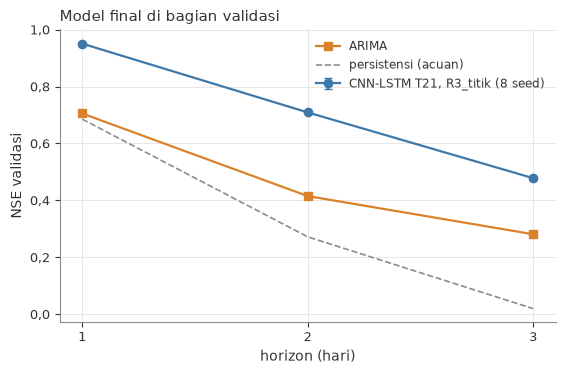

In [11]:
lama_b = pd.read_csv(HASIL / "baseline_validasi_per_run.csv")
cnn_f = FIN_R3[FIN_R3["model"] == "cnn_lstm"]
baris_f = []
for h in HORIZON:
    s_ = cnn_f[cnn_f["horizon"] == h]
    baris_f.append({"horizon": h, "CNN-LSTM T21 (R3_titik)": sel_(s_["NSE"].mean(), s_["NSE"].std()),
                    "KGE CNN-LSTM": koma(s_["KGE"].mean(), d=3),
                    **{nm: koma(float(lama_b[(lama_b["model"] == nm) & (lama_b["horizon"] == h)]["NSE"].iloc[0]), d=3)
                       for nm in ["ARIMA", "persistensi"]},
                    "KGE ARIMA": koma(float(lama_b[(lama_b["model"] == "ARIMA") & (lama_b["horizon"] == h)]["KGE"].iloc[0]), d=3),
                    "PICP 95% CNN-LSTM": koma(s_["PICP95"].mean(), d=3)})
TAB_FINAL = pd.DataFrame(baris_f).set_index("horizon")
print("NSE validasi (1.370 tanggal target per horizon); CNN-LSTM: rata-rata ± sb atas 8 seed")
print(TAB_FINAL.to_string())
for h in HORIZON:
    D = data_pilihan(h, **KONF_R)
    pers = metrik(ke_m3s(D["y_val"], D), ke_m3s(D["X_val"][:, -1, D["i_target"], 0], D))
    b_ = lama_b[(lama_b["model"] == "persistensi") & (lama_b["horizon"] == h)].iloc[0]
    assert abs(pers["NSE"] - b_["NSE"]) < 1e-4, "persistensi berbeda dengan notebook 01"
print("\npersistensi dihitung ulang pada data R3_titik sama dengan notebook 01")
simpan_f = pd.DataFrame({"horizon": HORIZON,
                         "NSE_CNN_LSTM_T21_R3": [cnn_f[cnn_f.horizon == h]["NSE"].mean() for h in HORIZON],
                         "sb_CNN_LSTM_T21_R3": [cnn_f[cnn_f.horizon == h]["NSE"].std() for h in HORIZON],
                         "NSE_ARIMA": [float(lama_b[(lama_b.model == "ARIMA") & (lama_b.horizon == h)]["NSE"].iloc[0]) for h in HORIZON],
                         "NSE_persistensi": [float(lama_b[(lama_b.model == "persistensi") & (lama_b.horizon == h)]["NSE"].iloc[0]) for h in HORIZON]})
simpan_f.round(5).to_csv(HASIL / "perbandingan_final_validasi.csv", index=False)

fig, ax = plt.subplots(figsize=(6.4, 3.8))
xh = np.array(HORIZON)
ax.errorbar(xh, simpan_f["NSE_CNN_LSTM_T21_R3"], yerr=simpan_f["sb_CNN_LSTM_T21_R3"], marker="o", lw=1.6, capsize=3,
            color=WARNA["utama"], label="CNN-LSTM T21, R3_titik (8 seed)")
ax.plot(xh, simpan_f["NSE_ARIMA"], marker="s", lw=1.6, color=PALET["oranye"], label="ARIMA")
ax.plot(xh, simpan_f["NSE_persistensi"], ls="--", lw=1.2, color=BATAS, label="persistensi (acuan)")
ax.set_xticks(xh); ax.set_xlabel("horizon (hari)"); ax.set_ylabel("NSE validasi"); sumbu_koma(ax, d=1)
ax.legend(fontsize=8.5); ax.set_title("Model final di bagian validasi", loc="left")
simpan_gambar(fig, "perbandingan_final_validasi")

### Hasil

| Horizon | CNN-LSTM T21, R3_titik (8 seed) | ARIMA | Persistensi (acuan) |
|---|---|---|---|
| 1 | 0,951 ± 0,004 | 0,705 | 0,686 |
| 2 | 0,709 ± 0,004 | 0,415 | 0,272 |
| 3 | 0,478 ± 0,006 | 0,281 | 0,020 |

NSE bagian validasi, 1.370 tanggal target per horizon.

- CNN-LSTM di atas ARIMA di setiap horizon: +0,246, +0,294, dan +0,197 NSE. KGE juga
  lebih tinggi (0,959 / 0,776 / 0,552 dibanding 0,850 / 0,588 / 0,409).
- ARIMA hanya sedikit di atas persistensi pada horizon 1 (0,705 dan 0,686), dan
  keunggulannya membesar di horizon 2 dan 3.
- PICP 95% MC Dropout CNN-LSTM turun dengan horizon: 0,895, 0,815, dan 0,591.
- Persistensi dihitung ulang pada data R3_titik dan sama dengan notebook 01.

## 21. Uji suku τ⁻¹ pada ragam MC Dropout

Dasar: [Gal2016] untuk ragam prediktif MC Dropout = ragam antarlintasan + τ⁻¹;
[Le2025] memakai ragam antarlintasan saja; penaksiran τ⁻¹ dari ragam residu bagian
latih dan derau N(0, τ⁻¹) pada lintasan untuk rentang 95%: pilihan sendiri

Ragam prediksi MC Dropout sejauh ini hanya ragam antarlintasan, seperti Le dkk.
(2025), dan PICP 95% validasi model final masih di bawah nominal (0,895 / 0,815 /
0,591). Menurut Gal dan Ghahramani (2016), ragam prediktif adalah ragam
antarlintasan ditambah τ⁻¹, presisi derau observasi. Model ini tidak memakai weight
decay, sehingga τ⁻¹ tidak bisa diturunkan dari hiperparameter dan ditaksir dari data.

Konfigurasi: CNN-LSTM T21 dengan data R3_titik, 8 seed × 3 horizon, bobot tersimpan
dari tahap 17 (tidak dilatih ulang), 1.000 lintasan.

- **τ⁻¹ per horizon dan seed**: MC Dropout 1.000 lintasan di bagian **latih**, lalu
  τ⁻¹ = ragam residu (y_obs − rata-rata lintasan) dalam m³/s. Ragam yang sama
  dihitung dalam skala baku dan dikembalikan ke m³/s (dikali std²) sebagai
  pemeriksaan.
- **Varian A** (sekarang): ±1σ = rata-rata ± simpangan baku antarlintasan; 95% =
  persentil 2,5–97,5% lintasan.
- **Varian B**: ±1σ = rata-rata ± √(sd² + τ⁻¹); 95% = persentil 2,5–97,5% lintasan
  yang masing-masing ditambah derau N(0, τ⁻¹) dalam m³/s, dengan benih tetap per seed
  dan horizon. Nilai negatif tidak dipotong.
- **Kriteria**: prediksi titik kedua varian identik. Dipilih varian dengan
  |PICP95 − 0,95| (rata-rata h1–3, per seed) lebih kecil; bila selisih kedua varian
  lebih kecil dari simpangan baku antar-seed varian yang lebih baik, keduanya setara
  dan dipilih A.

**Reproduksi.** Prediksi titik dari bobot tersimpan identik dengan tahap 17, tetapi
lintasan MC Dropout tidak bisa diulang persis: generator acak lapisan Dropout berada
pada keadaan sesudah latih ketika tahap 17 dijalankan, dan keadaan itu tidak ikut
tersimpan di file bobot. Karena itu A dan B dihitung dari **himpunan lintasan baru
yang sama**. Angka A baru dilaporkan berdampingan dengan tahap 17; selisih rata-rata
8 seed per horizon ≤ 0,002 dianggap konsisten (bila lebih, pekerjaan berhenti).
Lintasan validasi baru disimpan di `cache/mc_val_tau/` (float32, tidak masuk git)
beserta benih MC dan benih derau, sehingga hasil ini bisa diulang persis.

In [3]:
import keras
B_JSON_T = json.loads((HASIL / "pilihan_tahap_b.json").read_text())
CFG_T21 = B_JSON_T["model"]["cnn_lstm"]["cfg"]
FIN_T = pd.read_csv(HASIL / "tahap_r3_final_per_run.csv")
FIN_T = FIN_T[(FIN_T["model"] == "cnn_lstm") & (FIN_T["titik"] == B_JSON_T["model"]["cnn_lstm"]["titik"])]
assert len(FIN_T) == 24 and sorted(FIN_T["seed"].unique()) == list(range(8))
N_LINTASAN = pm.N_LINTASAN
MC_TAU = ROOT / "cache" / "mc_val_tau"; MC_TAU.mkdir(parents=True, exist_ok=True)
BENIH_DERAU = lambda h, s: 2016_000 + 100 * h + s                # benih derau varian B, dicatat per run

def rentang(o, S):
    """PICP dan MPIW untuk ±1σ (rata ± sb lintasan) dan persentil 2,5-97,5% dari matriks lintasan S (lintasan x sampel)."""
    mu, sd = S.mean(0), S.std(0)
    lo, hi = np.quantile(S, [0.025, 0.975], axis=0)
    return mu, sd, {"PICP68": float(np.mean((o >= mu - sd) & (o <= mu + sd))), "MPIW68": float(np.mean(2 * sd)),
                    "PICP95": float(np.mean((o >= lo) & (o <= hi))), "MPIW95": float(np.mean(hi - lo))}

baris_t, t0 = [], time.perf_counter()
for h in HORIZON:
    D = muat_latih_val(h, "V17", 8, "v2_R3_titik", "log1p")      # pagar data uji di dalam fungsi ini
    assert (D["idx_latih"] < pm.I_LATIH).all() and (D["idx_val"] >= pm.I_LATIH).all() and (D["idx_val"] < pm.I_VAL).all()
    Xl = pm.bentuk_masukan(D["X_latih"], "cnn_lstm", D["i_target"])
    Xv = pm.bentuk_masukan(D["X_val"], "cnn_lstm", D["i_target"])
    o_l, o_v = ke_m3s(D["y_latih"], D), ke_m3s(D["y_val"], D)
    for _, r in FIN_T[FIN_T["horizon"] == h].sort_values("seed").iterrows():
        s = int(r["seed"])
        keras.backend.clear_session()
        m = pm.bangun_model("cnn_lstm", CFG_T21, Xl.shape[1:])
        m.load_weights(pm.BOBOT / f"{r['id_run']}.weights.h5")
        with np.load(pm.MC_VAL / f"{r['id_run']}.npz") as f_:
            simpan = {k: f_[k].copy() for k in ["prediksi", "rata", "sb", "q025", "q975", "idx_val"]}
        assert np.array_equal(simpan["idx_val"], D["idx_val"])
        pred = ke_m3s(m.predict(Xv, batch_size=2048, verbose=0).ravel(), D)
        assert np.array_equal(pred, simpan["prediksi"]), f"bobot {r['id_run']} tidak menghasilkan prediksi tersimpan"
        # lintasan validasi baru (benih MC = seed run, sama dengan tahap 17); dipakai bersama oleh A dan B
        Sv = ke_m3s(pm.mc_dropout(m, Xv, N_LINTASAN, s), D).astype(np.float32)
        np.savez_compressed(MC_TAU / f"{r['id_run']}.npz", lintasan=Sv, idx_val=D["idx_val"], benih_mc=s,
                            benih_derau=BENIH_DERAU(h, s))
        mu_v, sd_v, A = rentang(o_v, Sv.astype(np.float64))
        A_lama = pm.ringkas_mc(r["id_run"])
        # tau^-1 dari bagian latih saja: indeks latih dipastikan sebelum dipakai
        idx_tau = D["idx_latih"]
        assert (idx_tau < pm.I_LATIH).all() and len(idx_tau) == len(D["y_latih"]), "indeks tau^-1 bukan indeks latih"
        Zl = pm.mc_dropout(m, Xl, N_LINTASAN, s)                        # skala baku
        res_z = D["y_latih"].astype(np.float64) - Zl.mean(0).astype(np.float64)
        tau_z = float(np.var(res_z))
        Sl = ke_m3s(Zl, D)
        res_m3s = o_l - Sl.mean(0)
        tau_inv = float(np.var(res_m3s))                                # tau^-1 dalam (m3/s)^2
        tau_z_m3s = tau_z * D["std"] ** 2
        assert np.isclose(tau_inv, tau_z_m3s, rtol=1e-4), "tau^-1 skala baku dan m3/s tidak konsisten"
        # varian B
        rng = np.random.default_rng(BENIH_DERAU(h, s))
        SvB = Sv.astype(np.float64) + rng.normal(0.0, np.sqrt(tau_inv), size=Sv.shape)
        _, _, B = rentang(o_v, SvB)
        sd_B = np.sqrt(sd_v ** 2 + tau_inv)
        B["PICP68"] = float(np.mean((o_v >= mu_v - sd_B) & (o_v <= mu_v + sd_B)))
        B["MPIW68"] = float(np.mean(2 * sd_B))
        baris_t.append({"horizon": h, "seed": s, "id_run": r["id_run"], "n_latih": len(idx_tau), "n_val": len(o_v),
                        "tau_inv_m3s2": tau_inv, "tau_inv_baku": tau_z, "tau_inv_baku_ke_m3s2": tau_z_m3s,
                        "sd_tau_m3s": np.sqrt(tau_inv), "bias_latih_m3s": float(res_m3s.mean()),
                        "sd_antarlintasan_val_rata_m3s": float(sd_v.mean()), "benih_mc_val": s, "benih_mc_latih": s,
                        "benih_derau": BENIH_DERAU(h, s),
                        "persen_lintasan_B_negatif": float((SvB < 0).mean() * 100),
                        "NSE": float(pm.nse(o_v, pred)),
                        **{f"{k}_A": v for k, v in A.items()}, **{f"{k}_B": v for k, v in B.items()},
                        "PICP68_A_tahap17": A_lama["PICP68"], "PICP95_A_tahap17": A_lama["PICP95"],
                        "MPIW68_A_tahap17": A_lama["MPIW68"], "MPIW95_A_tahap17": A_lama["MPIW95"]})
        del Zl, Sl, SvB
TAU = pd.DataFrame(baris_t)
print(f"waktu: {(time.perf_counter() - t0) / 60:.1f} menit; {len(TAU)} run")
# konsistensi varian A (lintasan baru) dengan tahap 17: selisih rata-rata 8 seed per horizon <= 0,002
kons = TAU.groupby("horizon")[["PICP68_A", "PICP68_A_tahap17", "PICP95_A", "PICP95_A_tahap17",
                                "MPIW95_A", "MPIW95_A_tahap17"]].mean()
kons["selisih_PICP68"] = kons["PICP68_A"] - kons["PICP68_A_tahap17"]
kons["selisih_PICP95"] = kons["PICP95_A"] - kons["PICP95_A_tahap17"]
print("varian A dari lintasan baru dibanding tahap 17 (rata-rata 8 seed):")
print(kons.round(4).to_string())
print(f"selisih per run maks: PICP ±1σ {(TAU['PICP68_A'] - TAU['PICP68_A_tahap17']).abs().max():.4f}, "
      f"PICP 95% {(TAU['PICP95_A'] - TAU['PICP95_A_tahap17']).abs().max():.4f}")
assert (kons[["selisih_PICP68", "selisih_PICP95"]].abs() <= 0.002).all().all(), \
    "varian A tidak konsisten dengan tahap 17 (selisih rata-rata > 0,002)"
print("konsisten: semua selisih rata-rata <= 0,002")
TAU.round(6).to_csv(HASIL / "uji_tau.csv", index=False)

I0000 00:00:1795598023.056207  507534 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5016 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:01:00.0, compute capability: 8.9


waktu: 20.2 menit; 24 run
varian A dari lintasan baru dibanding tahap 17 (rata-rata 8 seed):
         PICP68_A  PICP68_A_tahap17  PICP95_A  PICP95_A_tahap17  MPIW95_A  MPIW95_A_tahap17  selisih_PICP68  selisih_PICP95
horizon                                                                                                                    
1          0.6627            0.6623    0.8938            0.8949  101.9228          101.8855          0.0004         -0.0011
2          0.5380            0.5378    0.8151            0.8147  139.6802          139.7965          0.0002          0.0005
3          0.3596            0.3597    0.5908            0.5913  134.3288          134.3160         -0.0001         -0.0005
selisih per run maks: PICP ±1σ 0.0051, PICP 95% 0.0080
konsisten: semua selisih rata-rata <= 0,002


τ⁻¹ dari bagian latih (rata-rata ± sb antar-seed):
         tau_inv_m3s2  sb_tau  sd_tau_m3s  sd_antarlintasan_val  bias_latih  negatif_B_persen
horizon                                                                                      
1              723.51  273.38       26.49                 26.09        0.47              1.30
2             8902.19  665.10       94.29                 35.77       -2.12              9.81
3            21630.21  484.89      147.06                 34.40       -8.84             14.04
selisih relatif maks τ⁻¹ m3/s dibanding skala baku × std²: 4.6e-07

validasi, rata-rata ± sb antar-seed (8 seed); nominal ±1σ 0,683, 95% 0,95:
                     PICP ±1σ MPIW ±1σ (m³/s)       PICP 95% MPIW 95% (m³/s)
horizon varian                                                              
1       A       0,663 ± 0,084      52,2 ± 6,0  0,894 ± 0,031    101,9 ± 11,7
        B       0,856 ± 0,037     78,9 ± 11,6  0,958 ± 0,009    154,2 ± 22,8
2       A       0,538 ± 0,05

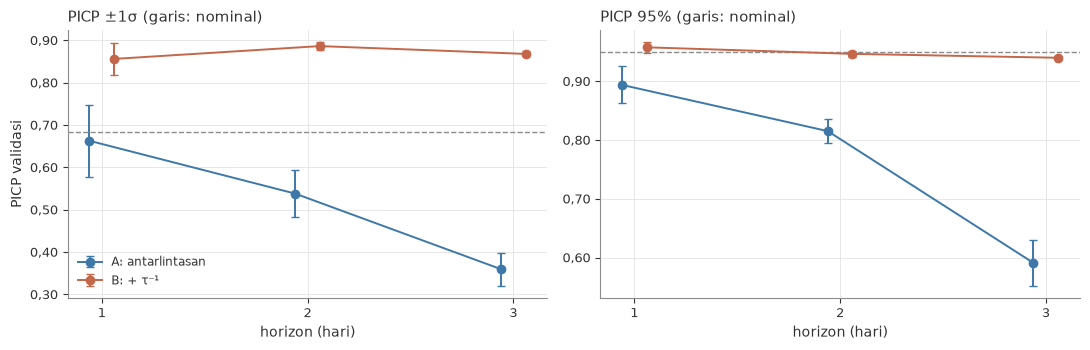

In [4]:
print("τ⁻¹ dari bagian latih (rata-rata ± sb antar-seed):")
tau_h = TAU.groupby("horizon").agg(tau_inv_m3s2=("tau_inv_m3s2", "mean"), sb_tau=("tau_inv_m3s2", "std"),
                                   sd_tau_m3s=("sd_tau_m3s", "mean"), sd_antarlintasan_val=("sd_antarlintasan_val_rata_m3s", "mean"),
                                   bias_latih=("bias_latih_m3s", "mean"), negatif_B_persen=("persen_lintasan_B_negatif", "mean"))
print(tau_h.round(2).to_string())
print(f"selisih relatif maks τ⁻¹ m3/s dibanding skala baku × std²: "
      f"{(TAU['tau_inv_m3s2'] / TAU['tau_inv_baku_ke_m3s2'] - 1).abs().max():.1e}")

def sel_t(a, s, d=3):
    return f"{koma(a, d=d)} ± {koma(s, d=d)}"
baris_r = []
for h in HORIZON:
    g_ = TAU[TAU["horizon"] == h]
    for v in "AB":
        baris_r.append({"horizon": h, "varian": v,
                        "PICP ±1σ": sel_t(g_[f"PICP68_{v}"].mean(), g_[f"PICP68_{v}"].std()),
                        "MPIW ±1σ (m³/s)": sel_t(g_[f"MPIW68_{v}"].mean(), g_[f"MPIW68_{v}"].std(), 1),
                        "PICP 95%": sel_t(g_[f"PICP95_{v}"].mean(), g_[f"PICP95_{v}"].std()),
                        "MPIW 95% (m³/s)": sel_t(g_[f"MPIW95_{v}"].mean(), g_[f"MPIW95_{v}"].std(), 1)})
print("\nvalidasi, rata-rata ± sb antar-seed (8 seed); nominal ±1σ 0,683, 95% 0,95:")
print(pd.DataFrame(baris_r).set_index(["horizon", "varian"]).to_string())

# kriteria: |PICP95 - 0,95| rata-rata h1-3 per seed
dev = TAU.assign(dev_A=(TAU["PICP95_A"] - 0.95).abs(), dev_B=(TAU["PICP95_B"] - 0.95).abs()).groupby("seed")[["dev_A", "dev_B"]].mean()
m_A, m_B, s_A, s_B = dev["dev_A"].mean(), dev["dev_B"].mean(), dev["dev_A"].std(), dev["dev_B"].std()
lebih_baik = "A" if m_A <= m_B else "B"
sb_acuan = s_A if lebih_baik == "A" else s_B
setara = abs(m_A - m_B) < sb_acuan
VARIAN_TAU = "A" if setara else lebih_baik
print(f"\n|PICP95 - 0,95| rata-rata h1-3: A {koma(m_A, d=3)} ± {koma(s_A, d=3)}, B {koma(m_B, d=3)} ± {koma(s_B, d=3)}")
print(f"selisih {m_A - m_B:+.4f}; sb antar-seed varian yang lebih baik ({lebih_baik}) {sb_acuan:.4f}; setara: {setara}")
print(f"varian terpilih: {VARIAN_TAU}")
print(f"MPIW 95% rata-rata h1-3: A {TAU['MPIW95_A'].mean():.1f} m3/s, B {TAU['MPIW95_B'].mean():.1f} m3/s; "
      f"NSE titik sama untuk A dan B: {TAU['NSE'].mean():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a_, (k_, nom) in zip(ax, [("PICP68", 0.683), ("PICP95", 0.95)]):
    for j, v in enumerate("AB"):
        g_ = TAU.groupby("horizon")[f"{k_}_{v}"]
        a_.errorbar(np.array(HORIZON) + (j - 0.5) * 0.12, g_.mean(), yerr=g_.std(), marker="o", capsize=3, lw=1.4,
                    color=[WARNA["utama"], WARNA["aksen"]][j], label={"A": "A: antarlintasan", "B": "B: + τ⁻¹"}[v])
    a_.axhline(nom, color=BATAS, ls="--", lw=1)
    a_.set_xticks(HORIZON); a_.set_xlabel("horizon (hari)"); sumbu_koma(a_, d=2)
    a_.set_title(f"{'PICP ±1σ' if k_ == 'PICP68' else 'PICP 95%'} (garis: nominal)", loc="left")
ax[0].set_ylabel("PICP validasi"); ax[0].legend(fontsize=8.5)
fig.tight_layout()
simpan_gambar(fig, "uji_tau_picp")

### Hasil

**Konsistensi varian A.** Dari lintasan baru, rata-rata 8 seed berbeda dengan tahap 17
paling banyak 0,0011 (PICP 95% h1: 0,894 dibanding 0,895); per run paling banyak 0,008.
Semua selisih rata-rata ≤ 0,002, jadi konsisten.

**τ⁻¹ dari bagian latih** (rata-rata ± sb antar-seed):

| Horizon | τ⁻¹ (m³/s)² | √τ⁻¹ (m³/s) | sd antarlintasan validasi (m³/s) | Lintasan B negatif |
|---|---|---|---|---|
| 1 | 724 ± 273 | 26 | 26 | 1,3% |
| 2 | 8.902 ± 665 | 94 | 36 | 9,8% |
| 3 | 21.630 ± 485 | 147 | 34 | 14,0% |

τ⁻¹ dalam m³/s sama dengan τ⁻¹ skala baku × std² (selisih relatif ≤ 5 × 10⁻⁷).

**Validasi, 8 seed** (nominal ±1σ 0,683; 95% 0,95):

| Horizon | Varian | PICP ±1σ | MPIW ±1σ (m³/s) | PICP 95% | MPIW 95% (m³/s) |
|---|---|---|---|---|---|
| 1 | A | 0,663 ± 0,084 | 52 ± 6 | 0,894 ± 0,031 | 102 ± 12 |
| 1 | B | 0,856 ± 0,037 | 79 ± 12 | 0,958 ± 0,009 | 154 ± 23 |
| 2 | A | 0,538 ± 0,056 | 72 ± 2 | 0,815 ± 0,021 | 140 ± 4 |
| 2 | B | 0,886 ± 0,009 | 206 ± 7 | 0,947 ± 0,005 | 403 ± 13 |
| 3 | A | 0,360 ± 0,039 | 69 ± 3 | 0,591 ± 0,039 | 134 ± 5 |
| 3 | B | 0,868 ± 0,006 | 304 ± 3 | 0,940 ± 0,003 | 592 ± 7 |

- **Varian terpilih: B.** |PICP95 − 0,95| rata-rata h1–3: A 0,183 ± 0,024, B 0,008 ± 0,003.
  Selisihnya 0,176, jauh di atas simpangan baku antar-seed B (0,003), jadi tidak setara.
- Ketidakpastian antarlintasan hampir tidak tumbuh dengan horizon (26–36 m³/s), sedangkan
  galat bagian latih tumbuh tajam (√τ⁻¹ 26 → 147 m³/s). Kekurangan cakupan varian A
  terutama berasal dari derau yang tidak dimodelkan, bukan dari ketidakpastian bobot.
- Harganya rentang yang jauh lebih lebar: MPIW 95% rata-rata h1–3 naik dari 125 menjadi
  383 m³/s (h3: 134 → 592 m³/s).
- B kelebihan cakupan pada ±1σ (0,86–0,89 dibanding 0,683) tetapi tepat di 95%. τ⁻¹ satu
  nilai konstan, sehingga galat yang menceng dan berekor tebal (kecil di hari biasa, besar di
  sekitar banjir) membuat ±1σ terlalu lebar untuk kebanyakan hari, sementara ekor 95% pas.
- Derau Gauss membuat 1–14% lintasan B bernilai negatif (tidak dipotong).
- NSE titik sama untuk A dan B (0,713). Bagian uji tidak dimuat; τ⁻¹ hanya dari indeks
  latih (assert).

Waktu jalan notebook:

In [30]:
print(f"waktu jalan notebook: {(time.time() - MULAI_JALAN) / 60:.1f} menit")
print(f"run di log: {len(baca_log())}")

waktu jalan notebook: 156.1 menit
run di log: 999
